# Machine Learning Lab: Chlorophyll-a Forecasting

**Objective:** Predict the daily concentration of Chlorophyll-a (`chlorophyll_a_mg_m3`) using historical environmental data. 
This notebook documents the full evolutionary process of our modeling pipeline, starting from raw data exploration, identifying pipeline vulnerabilities (like outliers and skewness), testing feature engineering hypotheses, and culminating in our final Lasso-Ridge architecture.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
from sklearn import linear_model
from sklearn.metrics import r2_score, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

## 1. Initial Observations
When analysing the given data, we saw that all of them contain outliers, from `chlorophyll_a_mg_m3` to the exogenous variables. The laboratory guide mentions that some sensors are subjected to noise and some measurements do not reflect the reality. In order to see the scale of this outliers, as well as to see the behaviour of the the various variables as a function of time, the following plots where the variables are scalled were created.

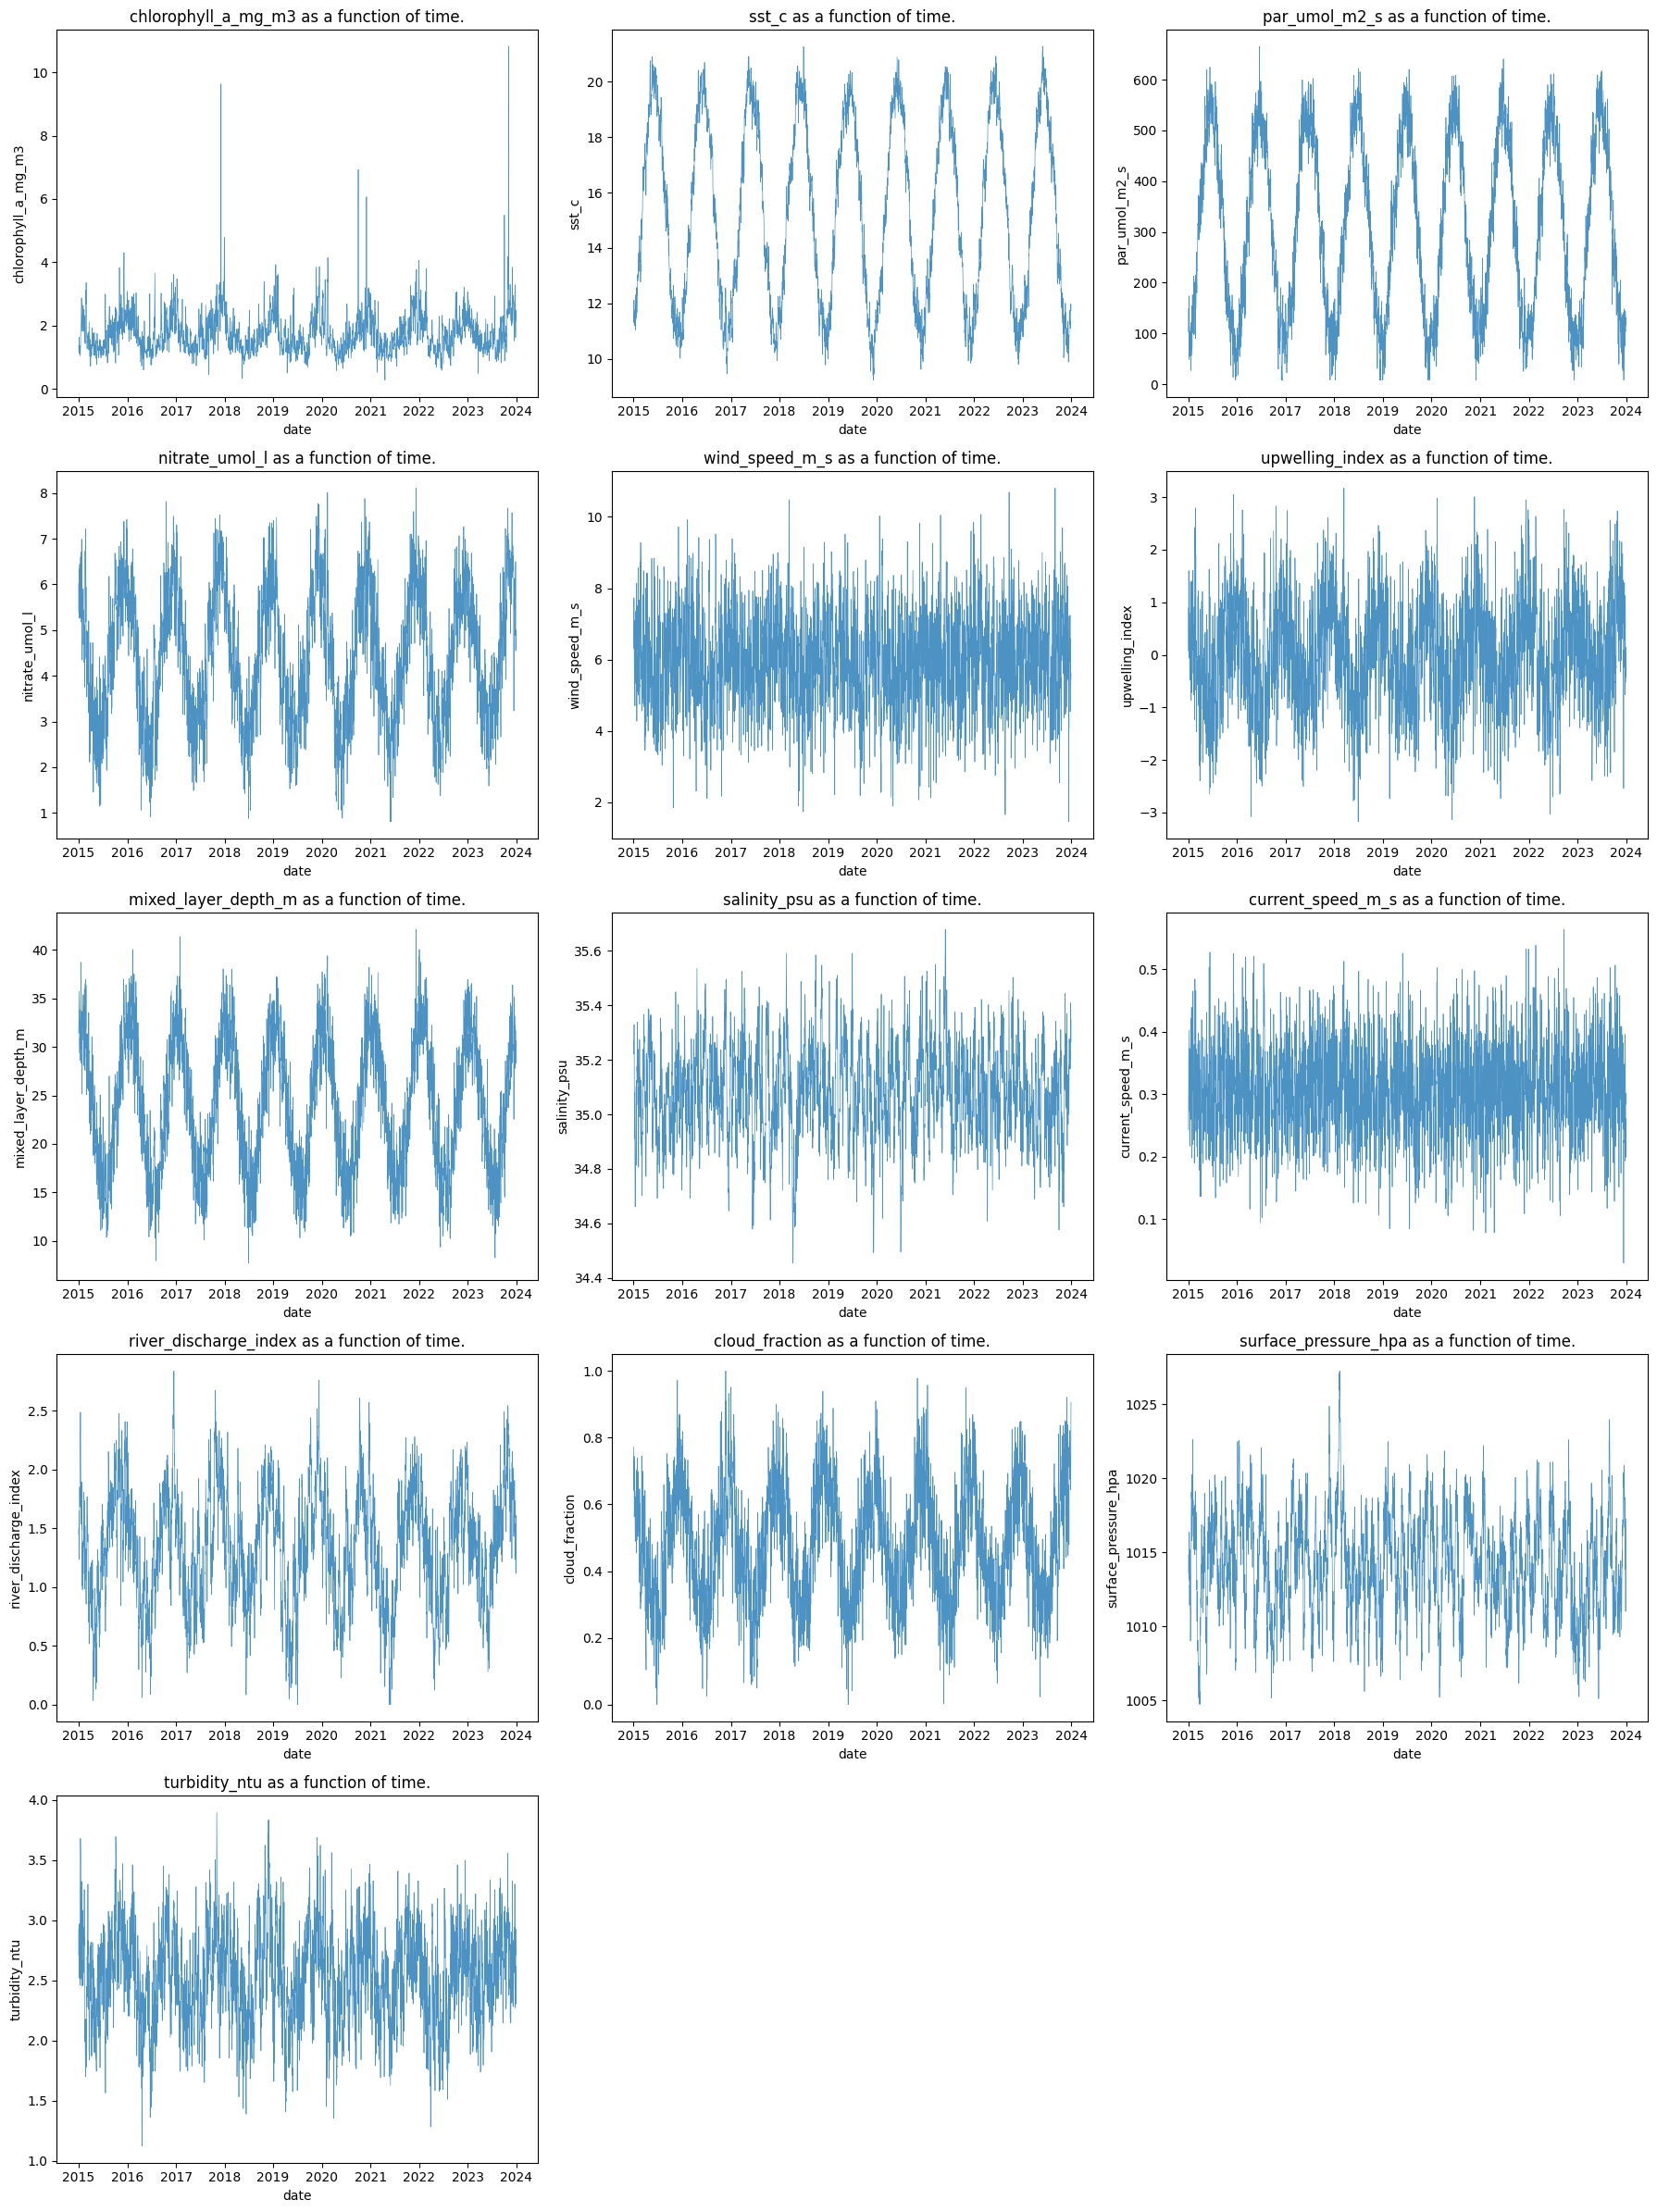

In [4]:
from build_lagged_features import build_lagged_frame
# Load raw data without any transformations
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

time_col = "date"
exogenous_cols = [col for col in df_raw.columns if col not in ["date"]]


plt.figure(figsize=(18, 24))
for i, feature in enumerate(exogenous_cols, 1):
    plt.subplot(5, 3, i)
    plt.plot(df_raw[time_col],df_raw[feature], alpha=0.8, linewidth=0.5)
    
    plt.title(f"{feature} as a function of time.")
    plt.xlabel(time_col)
    plt.ylabel(feature)

plt.tight_layout()
plt.show()


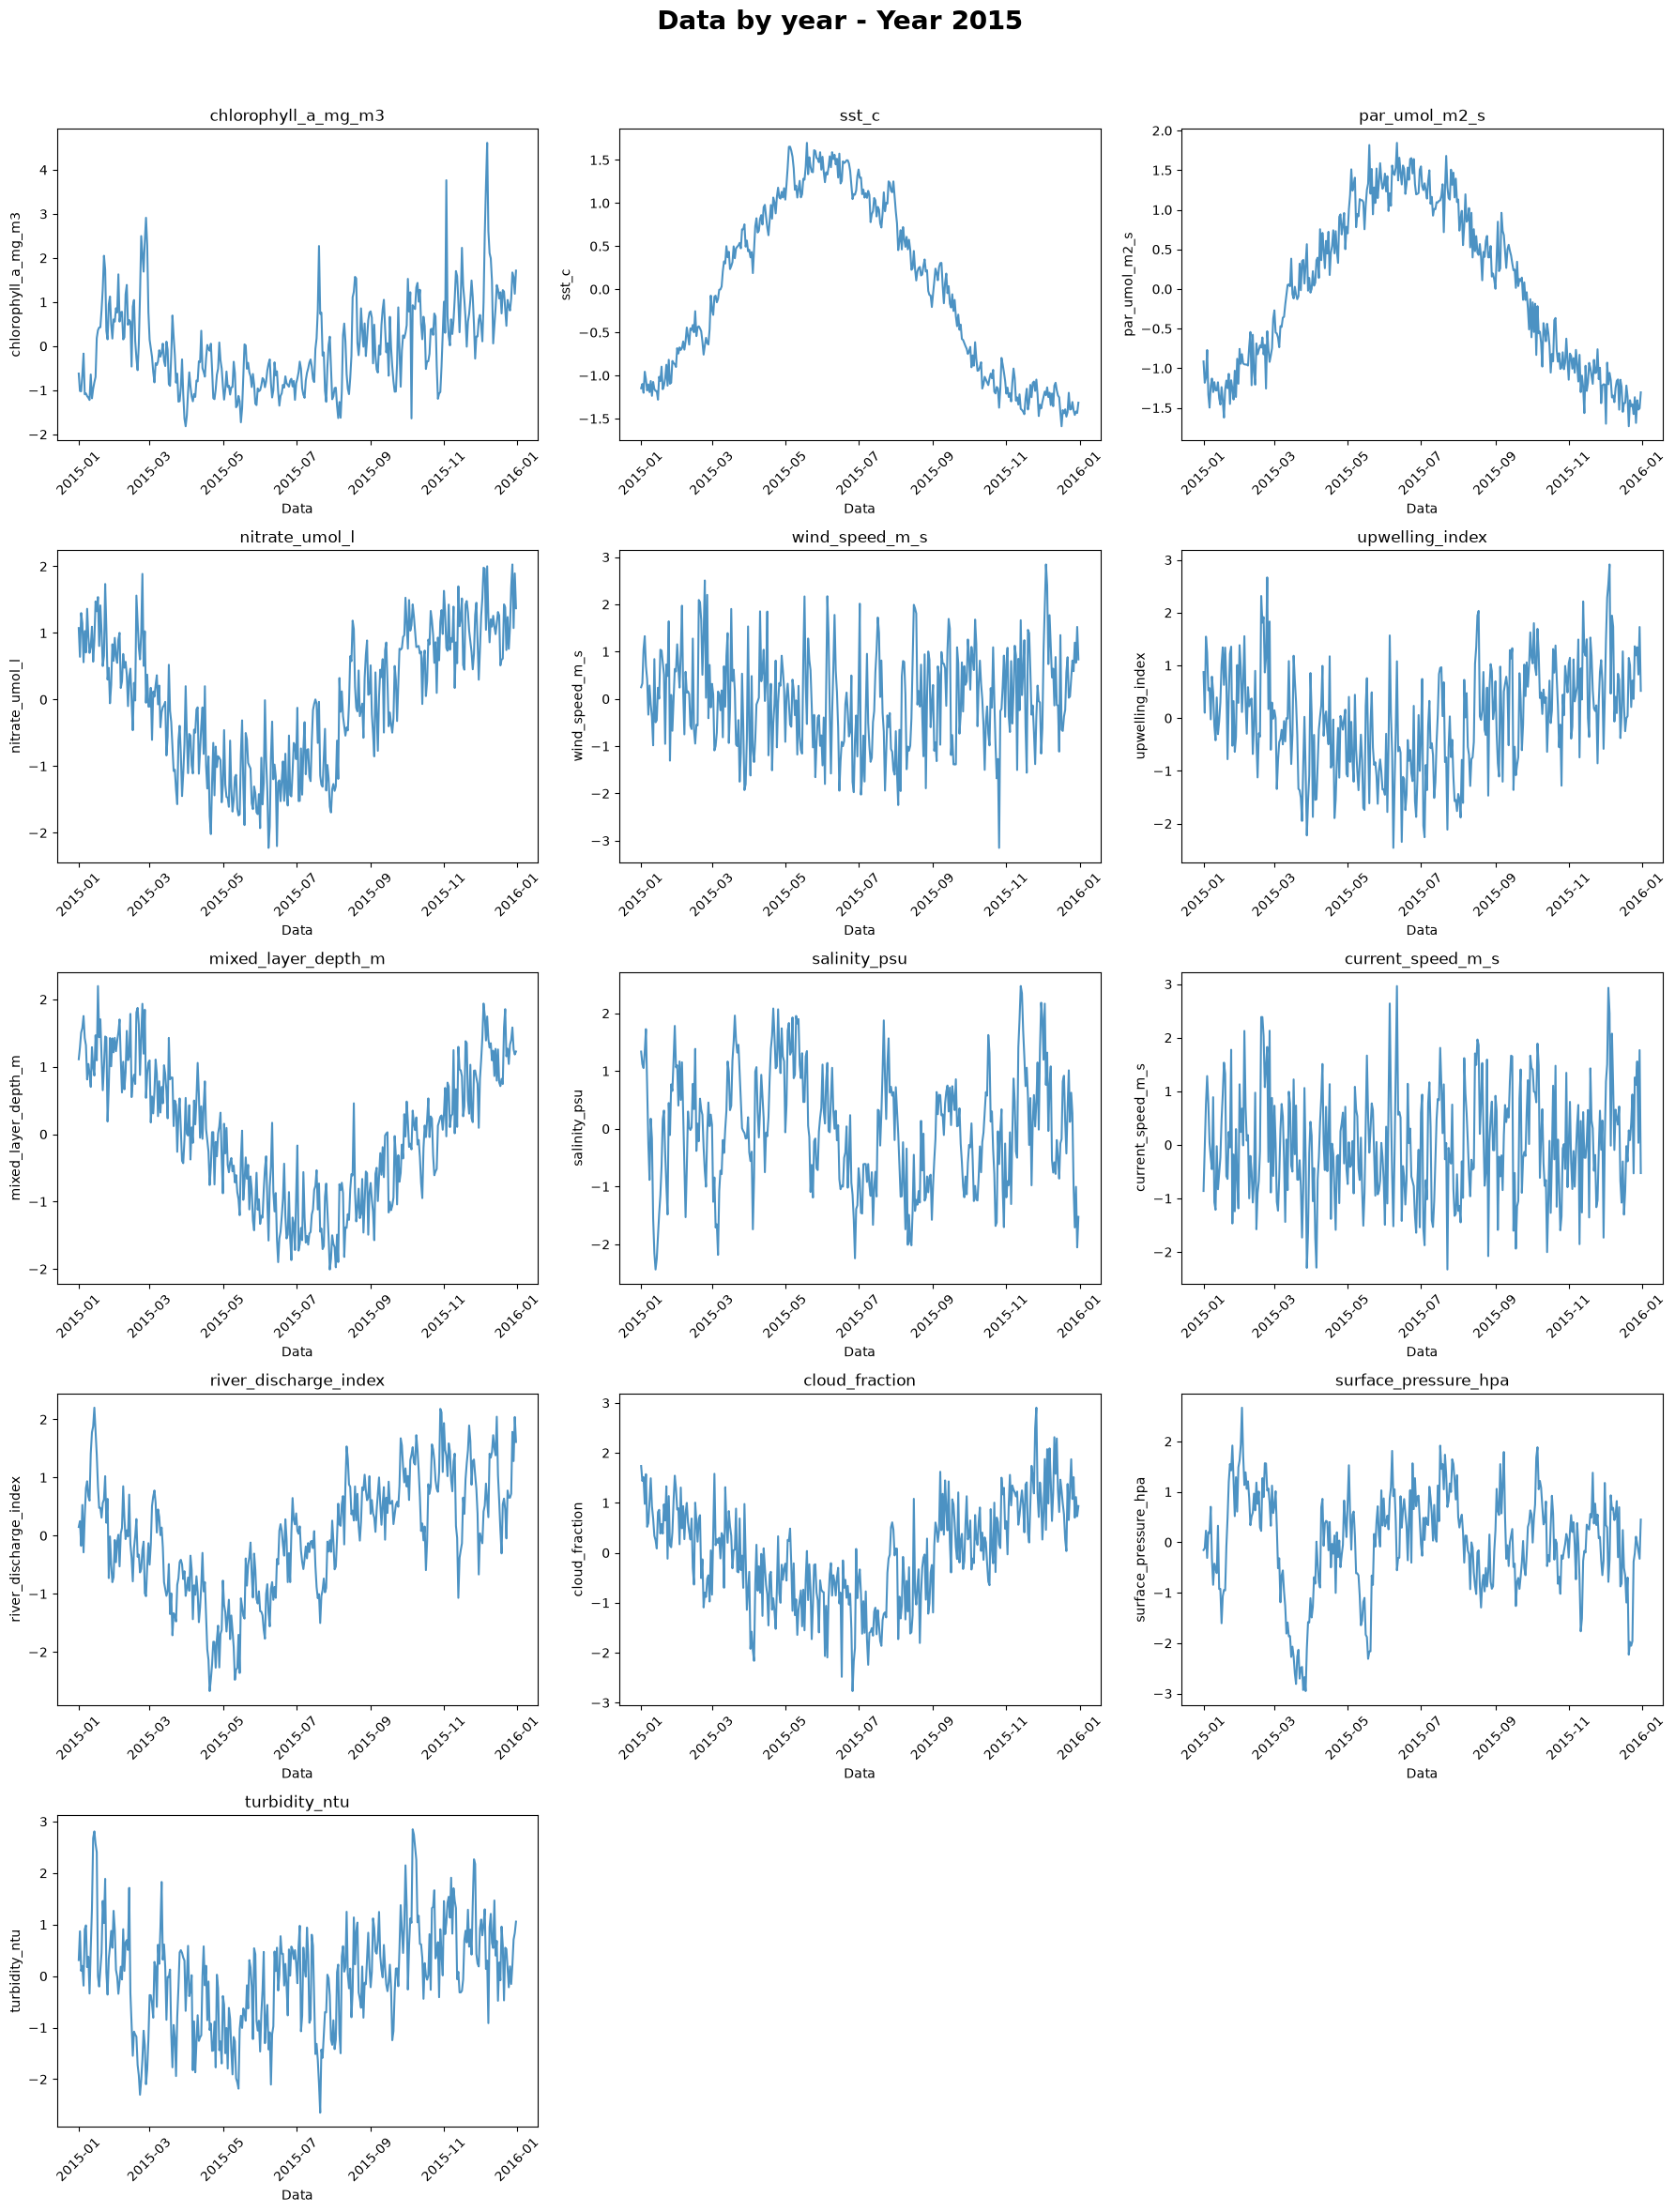

KeyboardInterrupt: 

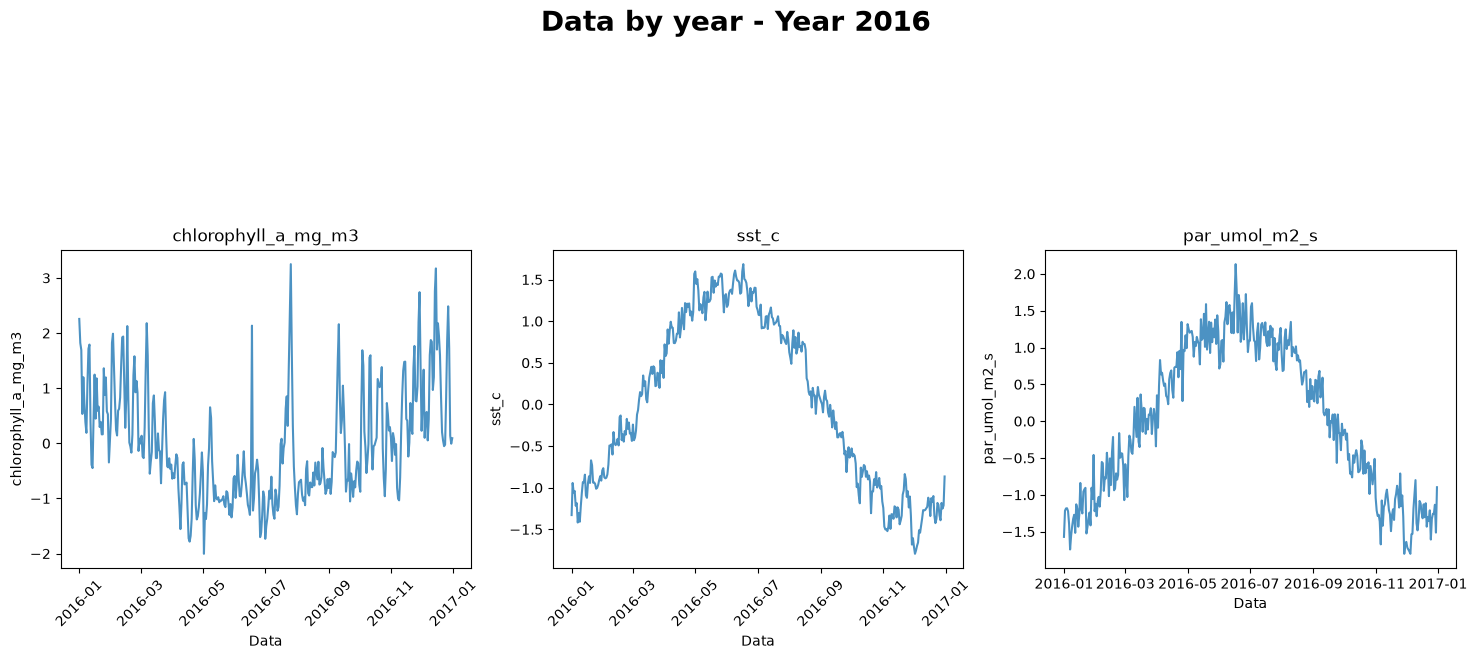

In [4]:
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")

df_raw["date"] = pd.to_datetime(df_raw["date"])

df_raw = df_raw.sort_values("date").reset_index(drop=True)


exogenous_cols = [col for col in df_raw.columns if col not in ["date"]]


single_year = df_raw["date"].dt.year.unique()




for year in single_year:

   

    df_year = df_raw[df_raw["date"].dt.year == year]

   

    scaler = StandardScaler()


    df_year[exogenous_cols] = scaler.fit_transform(df_year[exogenous_cols])

   

    plt.figure(figsize=(18, 24))

   

    plt.suptitle(f"Data by year - Year {year}", fontsize=20, fontweight='bold', y=0.98)

   

    for j, feature in enumerate(exogenous_cols, 1):

        plt.subplot(5, 3, j)


        plt.plot(df_year["date"], df_year[feature], alpha=0.8, linewidth=1.5)

       

        plt.title(feature)

        plt.xlabel("Data")

        plt.ylabel(feature)

       


        plt.xticks(rotation=45)


    plt.tight_layout(rect=[0, 0, 1, 0.96])

   

    plt.show()



The above plots allow us to conclude that chlorophyll normally shows some spikes that tend to be no bigger than 4 mg/m3, but in 2017, 2020 and 2023 there are some spikes that widly surpass that threshold. This plots also permit to see that some exogenous variables have high variations from day to day, while others present a more smooth behaviour.

## 1.1. Initial Data Exploration: Exogenous Features vs. Target

In order to define how many time-series lags each variable should be given, we need to understand  relationship between our exogenous environmental variables and the target variable (`chlorophyll_a_mg_m3`). 

Visualizing these relationships helps identify non-linearities, heteroscedasticity, and extreme outliers that might destabilize linear models later on.

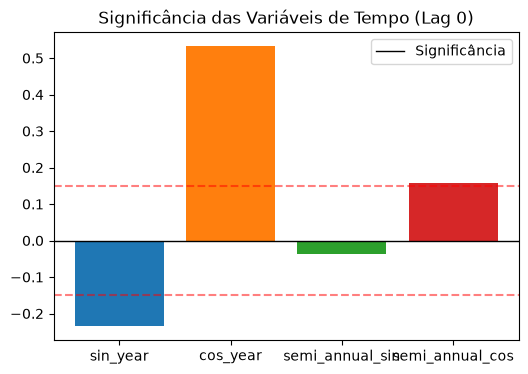

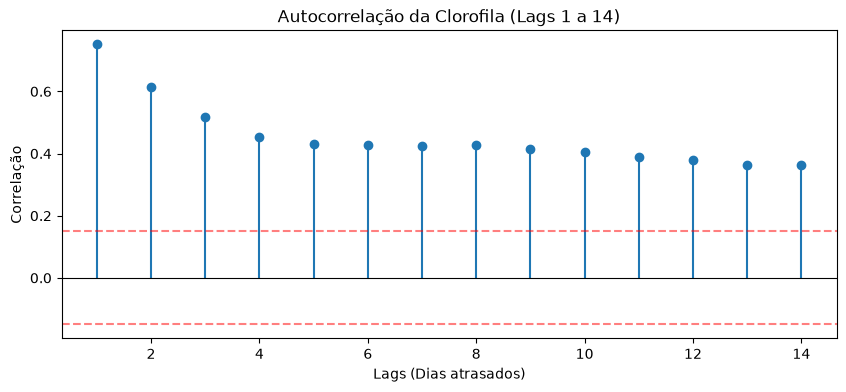

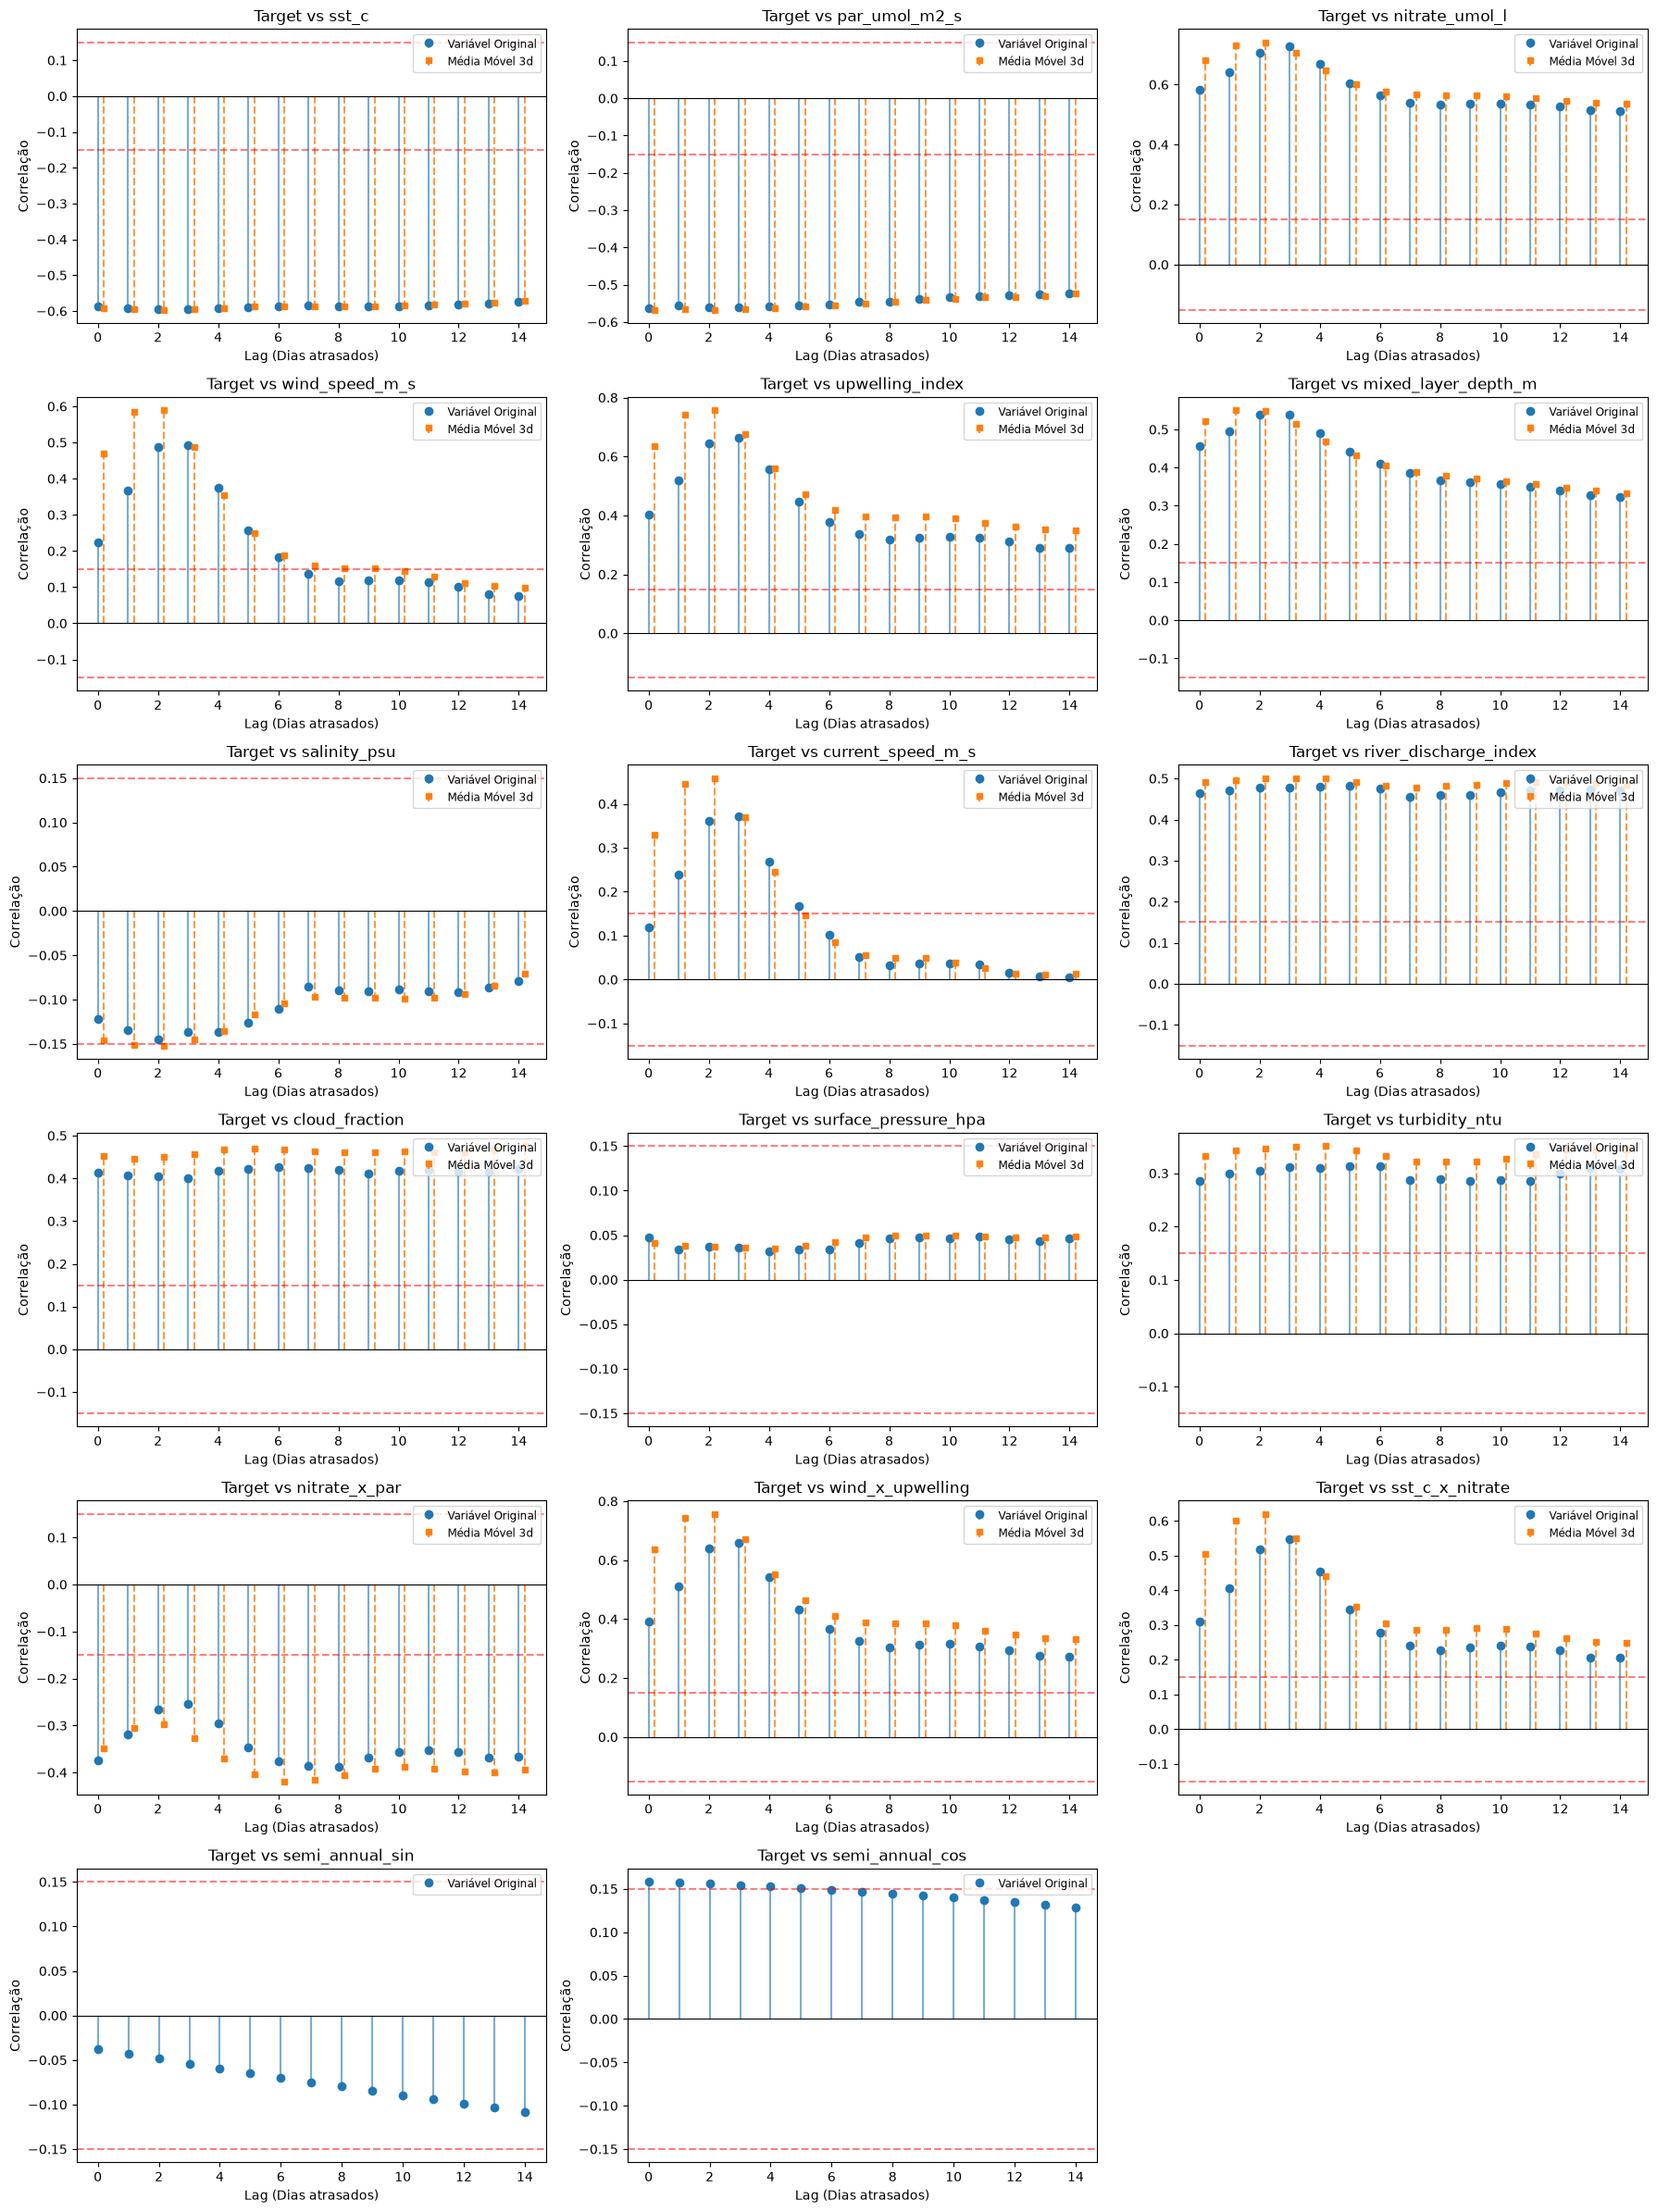

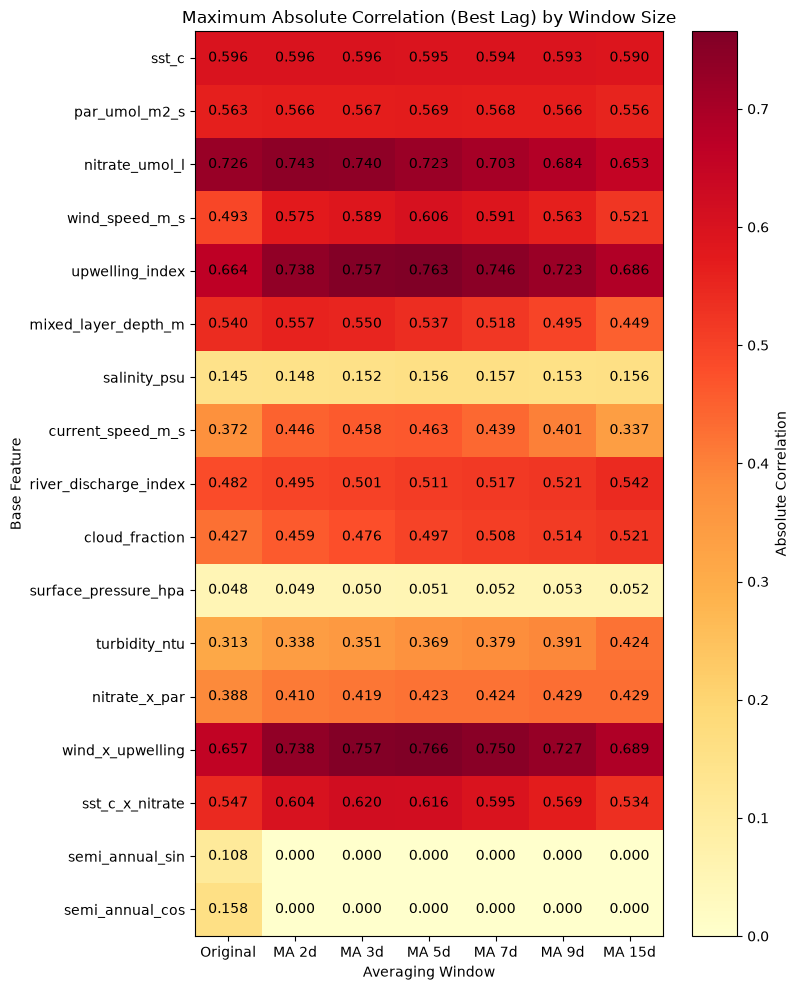

In [ ]:
# Load raw data without any transformations
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)



# Adding new columns that relate variables 
scaler = StandardScaler()
df_raw["nitrate_x_par"] = df_raw["nitrate_umol_l"] * df_raw["par_umol_m2_s"]
df_raw["wind_x_upwelling"] = df_raw["wind_speed_m_s"] * df_raw["upwelling_index"]
df_raw["sst_c_x_nitrate"] = df_raw["sst_c"] * df_raw["nitrate_umol_l"]

# Listing only the columns to which a Moving Average will be aplied 
window_sizes = [2, 3, 5, 7, 9, 15]
exogenous_cols_mv = df_raw.drop(columns=["date", "chlorophyll_a_mg_m3"]).columns
conf_level = 0.15

# GENERATE ALL MOVING AVERAGES HERE
for window in window_sizes:
    for feature in exogenous_cols_mv:
        df_raw[f"{feature}_average_{window}"] = df_raw[feature].rolling(window=window, min_periods=1).mean()

cols_to_scale = df_raw.columns.drop("date")
df_raw[cols_to_scale] = scaler.fit_transform(df_raw[cols_to_scale])

day_of_year = df_raw["date"].dt.dayofyear

# Apply the trigonometric formulas for seasonality
df_raw["sin_year"] = np.sin(2 * np.pi * day_of_year / 365.25)
df_raw["cos_year"] = np.cos(2 * np.pi * day_of_year / 365.25)
df_raw["semi_annual_sin"] = np.sin(4 * np.pi * day_of_year / 365.25)
df_raw["semi_annual_cos"] = np.cos(4 * np.pi * day_of_year / 365.25)

# Calculate their direct significance (Pearson correlation)
corr_sin = df_raw["chlorophyll_a_mg_m3"].corr(df_raw["sin_year"])
corr_cos = df_raw["chlorophyll_a_mg_m3"].corr(df_raw["cos_year"])
corr_sin_semi = df_raw["chlorophyll_a_mg_m3"].corr(df_raw["semi_annual_sin"])
corr_cos_semi = df_raw["chlorophyll_a_mg_m3"].corr(df_raw["semi_annual_cos"])

# Plot the significance statically
plt.figure(figsize=(6, 4))
plt.bar(["sin_year", "cos_year","semi_annual_sin", "semi_annual_cos" ], [corr_sin, corr_cos, corr_sin_semi, corr_cos_semi], color=['tab:blue', 'tab:orange', 'tab:green','tab:red'])
plt.axhline(0, color='black', linewidth=1)
plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
plt.title("Significância das Variáveis de Tempo (Lag 0)")
plt.legend(["Significância"])
plt.show()

target_col = "chlorophyll_a_mg_m3"
max_lags = 15

# Autocorrelação da Clorofila
acf_values = [df_raw[target_col].corr(df_raw[target_col].shift(lag)) for lag in range(1, max_lags)]

plt.figure(figsize=(10, 4))
plt.stem(range(1, max_lags), acf_values, basefmt=" ")
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
plt.title(f"Autocorrelação da Clorofila (Lags 1 a {max_lags-1})")
plt.xlabel("Lags (Dias atrasados)")
plt.ylabel("Correlação")
plt.show()

# Isolar as variáveis originais e as interações (ignorando todas as médias móveis e variáveis de tempo)
base_features = [col for col in df_raw.columns if "_average_" not in col and col not in ["date", target_col, "sin_year", "cos_year", "semi_annual_sin","semi_anual_cos"]]

num_features = len(base_features)
num_cols = 3
num_rows = (num_features + num_cols - 1) // num_cols 

plt.figure(figsize=(18, 4 * num_rows))

for i, feature in enumerate(base_features, 1):
    plt.subplot(num_rows, num_cols, i)
    
    # Original feature correlation
    ccf_values_raw = [df_raw[target_col].corr(df_raw[feature].shift(lag)) for lag in range(0, max_lags)]
    lags_raw = np.arange(0, max_lags)
    
    # Plotting raw variable (Blue Circles)
    markerline1, stemlines1, baseline1 = plt.stem(lags_raw, ccf_values_raw, basefmt=" ", label="Variável Original")
    plt.setp(markerline1, color='tab:blue', markersize=6)
    plt.setp(stemlines1, color='tab:blue', alpha=0.6)
    
    # FILTER TO ONLY PLOT THE 3-DAY AVERAGE ON THE STEM PLOTS
    avg_feature = f"{feature}_average_3"
    if avg_feature in df_raw.columns:
        ccf_values_avg = [df_raw[target_col].corr(df_raw[avg_feature].shift(lag)) for lag in range(0, max_lags)]
        
        # Offset the x-axis slightly by 0.2 so the lines do not overlap
        lags_avg = np.arange(0, max_lags) + 0.2 
        
        # Plotting averaged variable (Orange Squares)
        markerline2, stemlines2, baseline2 = plt.stem(lags_avg, ccf_values_avg, basefmt=" ", label="Média Móvel 3d")
        plt.setp(markerline2, color='tab:orange', markersize=5, marker='s')
        plt.setp(stemlines2, color='tab:orange', linestyle='--', alpha=0.8)

    plt.axhline(0, color='black', linewidth=0.8)
    plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
    plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
    
    plt.title(f"Target vs {feature}")
    plt.xlabel("Lag (Dias atrasados)")
    plt.ylabel("Correlação")
    plt.legend(loc="upper right", fontsize='small')

plt.tight_layout()
plt.show()


heatmap_data = []
column_labels = ["Original"] + [f"MA {w}d" for w in window_sizes]

for feature in base_features:
    # Find the maximum absolute correlation for the original variable across all lags
    corrs_raw = [df_raw[target_col].corr(df_raw[feature].shift(lag)) for lag in range(0, max_lags)]
    max_raw = max(corrs_raw, key=abs)
    
    row_data = [abs(max_raw)]
    
    # Find the maximum absolute correlation for ALL moving average windows
    for window in window_sizes:
        avg_feature = f"{feature}_average_{window}"
        if avg_feature in df_raw.columns:
            corrs_avg = [df_raw[target_col].corr(df_raw[avg_feature].shift(lag)) for lag in range(0, max_lags)]
            max_avg = max(corrs_avg, key=abs)
            row_data.append(abs(max_avg))
        else:
            row_data.append(0.0) # Fallback if missing
            
    heatmap_data.append(row_data)

# Convert to a 2D numpy array for matplotlib
heatmap_array = np.array(heatmap_data)

# Plotting the heatmap natively in Matplotlib
fig, ax = plt.subplots(figsize=(8, 10))
cax = ax.imshow(heatmap_array, cmap="YlOrRd", aspect="auto")

# Configure the axes ticks and labels
ax.set_xticks(np.arange(len(column_labels)))
ax.set_yticks(np.arange(len(base_features)))
ax.set_xticklabels(column_labels)
ax.set_yticklabels(base_features)

# Loop over the data and overlay the exact correlation numbers on the colored squares
for i in range(len(base_features)):
    for j in range(len(column_labels)):
        ax.text(j, i, f"{heatmap_array[i, j]:.3f}", ha="center", va="center", color="black")

plt.title("Maximum Absolute Correlation (Best Lag) by Window Size")
plt.xlabel("Averaging Window")
plt.ylabel("Base Feature")
plt.colorbar(cax, label="Absolute Correlation")
plt.tight_layout()
plt.show()

The second plot shows, as expected, that the lags of chlorophyll have a large correlation with the value of tyhe current day. The following plots allow us to see the correlation between the lags of different variables and the chlorophyll at the day we want to estimate to understand if these variables really affect the final result. A threshold of 0.15 was established to 'cut' the lags of the lag list that needs to be given to the function `build_lagged_frame`. The final plot shows the correlation of different variables if a moving average of a certain amount of days is considered, allowing for some future tuning in the following sections.

## 2. Baseline results & Methedology

Our baseline approach involves generating historical lag features (1-15 days for the target, 0-15 days for exogenous variables) and encoding the day of the year cyclically. 

In this initial phase, we scale the data but **do not** apply target transformations or outlier smoothing. This establishes a baseline to measure future pipeline improvements against.

In [ ]:


DATE = "date"
TARGET = "chlorophyll_a_mg_m3"

defined_lags = {
    TARGET: list(range(1, 15)),
    "sst_c": list(range(0, 15)),
    "par_umol_m2_s": list(range(0, 15)),
    "nitrate_umol_l": list(range(0, 15)),
    "wind_speed_m_s": list(range(0, 15)),
    "upwelling_index": list(range(0, 15)),
    "mixed_layer_depth_m": list(range(0, 15)),
    "salinity_psu": list(range(0, 15)),
    "current_speed_m_s": list(range(0, 15)),
    "river_discharge_index": list(range(0, 15)),
    "cloud_fraction": list(range(0, 15)),
    "surface_pressure_hpa": list(range(0, 15)),
    "turbidity_ntu": list(range(0, 15)),
}

# Build baseline features using the imported function
df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)

# Chronological split (Train, Validation, Test)
lower_sep = -2*365
higher_sep = -365

X_base = df_lagged.drop(columns=[DATE, TARGET])
Y_base = df_lagged[TARGET]

X_train_base = X_base.iloc[:lower_sep]
X_val_base = X_base.iloc[lower_sep:higher_sep]
X_test_base = X_base.iloc[higher_sep:]

Y_train_base = Y_base.iloc[:lower_sep]
Y_val_base = Y_base.iloc[lower_sep:higher_sep]
Y_test_base = Y_base.iloc[higher_sep:]

# Baseline Scaling
scaler_base = StandardScaler()
X_train_scaled_base = pd.DataFrame(scaler_base.fit_transform(X_train_base), columns=X_train_base.columns)
X_val_scaled_base = pd.DataFrame(scaler_base.transform(X_val_base), columns=X_val_base.columns)
X_test_scaled_base = pd.DataFrame(scaler_base.transform(X_test_base), columns=X_test_base.columns)

# Baseline Lasso Fit
baseline_lasso = linear_model.Lasso(alpha=0.0001, max_iter=10000)
baseline_lasso.fit(X_train_scaled_base, Y_train_base)

baseline_val_preds = baseline_lasso.predict(X_val_scaled_base)
baseline_test_preds = baseline_lasso.predict(X_test_scaled_base)

print(f"Baseline Validation R^2: {r2_score(Y_val_base, baseline_val_preds):.4f}")
print(f"Baseline Validation MAE: {mean_absolute_error(Y_val_base, baseline_val_preds):.4f}")
print(f"Baseline Test R^2: {r2_score(Y_test_base, baseline_test_preds):.4f}")
print(f"Baseline Test MAE: {mean_absolute_error(Y_test_base, baseline_test_preds):.4f}")

Baseline Validation R^2: 0.8198
Baseline Validation MAE: 0.1800
Baseline Test R^2: 0.4993
Baseline Test MAE: 0.2303


### 2.1 The Danger of Data Leakage: 2-Way vs. 3-Way Splits

A common pitfall in machine learning is using a simple 2-way split (Train/Test) and tuning hyperparameters directly on the test set. This leaks information about the unseen future data into the model configuration, resulting in an artificially inflated performance metric that will not hold up when testing with new data.

Furthermore, tuning on the Test set causes the model to select a different underlying architecture (in Lasso's case, the number of retained features). It will adjust its sparsity to artificially "fit" the noise in the Test set, completely changing which environmental variables are deemed important.

To demonstrate this, we will compare two approaches while keeping the training data strictly identical:
1. **Flawed 2-Way Split:** We train on the Train set, but pick the best `alpha` by checking which one scores highest directly on the Test set.
2. **Proper 3-Way Split:** We train on the Train set, pick the best `alpha` using the Validation set, and then test *only once* on the Test set to get an honest metric.

In [ ]:
alphas_to_test = np.logspace(-4, -2, 50)

print("--- Flawed 2-Way Split (Tuning on Test Set) ---")
best_test_r2_flawed = -float('inf')
best_alpha_flawed = None
flawed_features_kept = 0

for alpha in alphas_to_test:
    flawed_model = linear_model.Lasso(alpha=alpha, max_iter=10000)
    flawed_model.fit(X_train_scaled_base, Y_train_base)
    
    # DATA LEAKAGE: Peeking at the Test set during the tuning loop!
    test_preds_flawed = flawed_model.predict(X_test_scaled_base)
    test_r2_flawed = r2_score(Y_test_base, test_preds_flawed)
    
    if test_r2_flawed > best_test_r2_flawed:
        best_test_r2_flawed = test_r2_flawed
        best_alpha_flawed = alpha
        flawed_features_kept = np.sum(flawed_model.coef_ != 0)

print(f"Chosen Alpha: {best_alpha_flawed}")
print(f"Features Kept by Model: {flawed_features_kept} ")
print(f"Reported Test R^2: {best_test_r2_flawed:.4f} \n")


print("--- Proper 3-Way Split (Tuning on Validation Set) ---")
best_val_r2_proper = -float('inf')
best_alpha_proper = None

# Step 1 & 2: Train and Tune using strictly Train/Val splits
for alpha in alphas_to_test:
    proper_model = linear_model.Lasso(alpha=alpha, max_iter=10000)
    proper_model.fit(X_train_scaled_base, Y_train_base)
    
    # NO LEAKAGE: Using the Validation set to make decisions
    val_preds_proper = proper_model.predict(X_val_scaled_base)
    val_r2_proper = r2_score(Y_val_base, val_preds_proper)
    
    if val_r2_proper > best_val_r2_proper:
        best_val_r2_proper = val_r2_proper
        best_alpha_proper = alpha

# Step 3: Test exactly once using the chosen alpha
final_proper_model = linear_model.Lasso(alpha=best_alpha_proper, max_iter=10000)
final_proper_model.fit(X_train_scaled_base, Y_train_base)
proper_test_preds = final_proper_model.predict(X_test_scaled_base)
proper_test_r2 = r2_score(Y_test_base, proper_test_preds)
proper_features_kept = np.sum(final_proper_model.coef_ != 0)

print(f"Chosen Alpha: {best_alpha_proper}")
print(f"Features Kept by Model: {proper_features_kept} ")
print(f"True Unbiased Test R^2: {proper_test_r2:.4f}")
print(f"\nGap in reported performance: {(best_test_r2_flawed - proper_test_r2):.4f}")

--- Flawed 2-Way Split (Tuning on Test Set) ---
Chosen Alpha: 0.005
Features Kept by Model: 56 
Reported Test R^2: 0.5140 

--- Proper 3-Way Split (Tuning on Validation Set) ---
Chosen Alpha: 0.05
Features Kept by Model: 10 
True Unbiased Test R^2: 0.5018

Gap in reported performance: 0.0123


This results show that, in order to obtain better results in the test split, the 2-Way-Split chose `alpha` = 0.005. This will lead to an overfit of the test data, and adopting a policy of maximizing R^2 based in this should not be done. With the 3-Way-Split, since there is a middle set for validation, with respect to who the optimization of the hyperparameters is done, the test data is only use for a real evaluation. This approach is closer to the evaluation procedure that we will face.

## 2.2 Time Series Cross Validation

Time Series Cross-Validation extends traditional cross-validation techniques to handle the temporal structure inherent in time series data. Unlike traditional cross-validation, where random data splits are used, Time Series Cross-Validation (TSCV) preserves the temporal order of observations. It ensures that the model is evaluated on past data and tested on future data, mimicking real-world forecasting scenarios. Adapted from [1](https://www.geeksforgeeks.org/machine-learning/time-series-cross-validation/)

In this particular study it was defined that the split would be by year, reserving one full year for testing, as done in the 3 way split. The cross validation would then be done using an expanding training window, tuning hyperparameters on following year. In order to ensure sufficient data, as the model has many parameters, the minnimum training split is 4 years.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit



# Last year of all is the final test
test_size = 365

# cv refers to cross validation
X_cv= X_base.iloc[:-test_size].copy()
Y_cv = Y_base.iloc[:-test_size].copy()

# Creating the split for cross validation
# At least 4 years of training data for the first plit
# After that, one year is added each time
validation_years = [2019, 2020, 2021, 2022]
cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []
for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]

    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx))

# Starting here the optimization using cross validation
    best_r2_cross = -float('inf')
    best_alpha_cross = None


for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold, X_val_fold = X_cv.iloc[train_index].copy(), X_cv.iloc[val_index].copy()
        
        Y_train_fold, Y_val_fold = Y_cv.iloc[train_index].copy(), Y_cv.iloc[val_index].copy()

        # Scalling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        # scalling based on the mean of the test data p
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  

            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Prever e reverter o logaritmo para avaliar em mg/m3 reais
        preds_lasso = clf_lasso.predict(X_val_fold_scaled)
        
        
        vector_r2_scores.append(r2_score(Y_val_fold, preds_lasso))
        mean_r2 = np.mean(vector_r2_scores)


    # Calculates the mean R^2 score for all the time splits for the same alpha


    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha
scaler_final = StandardScaler()

X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_cv), columns=X_cv.columns)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_test_base), columns=X_test_base.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_final, Y_cv)
predicts_cross_test = final_cross_model.predict(X_test_scaled)
cross_test_r2 = r2_score(Y_test_base, predicts_cross_test)
cross_features_kept = np.sum(final_cross_model.coef_ != 0)

print(f"Chosen Alpha (TSCV): {best_alpha_cross}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Test R^2: {cross_test_r2:.4f}")


NameError: name 'X_base' is not defined

## 3. Types of Preprocessing used

Until now the raw data has been used. However, it is of interest to apply some preprocessing to it in the training phase to obtain better results. In that sprit, the following approaches were explored:

1. **Applying the logaritm to the chlorophyll data**: After some research, we found that applying the log to the target variable may help in the reduction of outliers, as per [2](https://www.geeksforgeeks.org/data-analysis/log-normalization-for-outliers-convert-skewed-data-to-normal-distribution/) ;
2. **Outlier Smoothing**: Since large spikes were identified in the chlorophyll data that can be considered as not normal, a way to not train the model with it is to identifie the values that stand out of the `[-X, X]` standard deviation range and use an average of Y previous days. A study of this values is conducted and evaluated using the validation and test results.
3. **Clipping of Exagenous Variables**: Since that in a normalized set of data an outlier can be considered as any value that falls of the range of `[-3, 3]` standard deviations, a prossible approach is to restrict the values that fall out of this interval as the maximum possible values of the intervall, -3 and 3.
4. **New Variables**: After some research on the topic, we discovered that some variable have a higher correlation with chlorophyll combined rather than sperated. In that spirit, some new variables were created and tested.
5. **Semi Annual Sinusoidals**: As the behaviour of the clorophyll might follow a seasonal behaviour correlated to the 4 seanos, aditional sinusoidal waves were added to take that into account
6. **Moving Average**: According to the heatmap shown in section 1, averages of some features had correlations to clorophyll significantly greater than the original feature

According to what was explained before, the `defined_lags` list will already not contain the lags that were evaluated in section 1 as not been correlated with the chlorophyll of the day we want to predict. 



In [ ]:
# Applying the log to the chlorophyll data

df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)
DATE = "date"
TARGET = "chlorophyll_a_mg_m3"
high_limit = 15
low_limit = 0
df_raw[TARGET] = np.log1p(df_raw[TARGET])

defined_lags = {
    "chlorophyll_a_mg_m3": list(range(1, high_limit)),
    "sst_c": list(range(low_limit, high_limit)),
    "par_umol_m2_s": list(range(low_limit, high_limit)), 
    "nitrate_umol_l": list(range(low_limit, high_limit)),
    "wind_speed_m_s": list(range(low_limit, high_limit)),
    "upwelling_index": list(range(low_limit, high_limit)),
    "mixed_layer_depth_m": list(range(low_limit, high_limit)),
    "salinity_psu": list(range(low_limit, high_limit)),
    "current_speed_m_s": list(range(low_limit, high_limit)),
    "river_discharge_index": list(range(low_limit, high_limit)),
    "cloud_fraction": list(range(low_limit, high_limit)),
    "surface_pressure_hpa": list(range(low_limit, high_limit)),
    "turbidity_ntu": list(range(low_limit, high_limit)),
}


df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
X_ablation = df_lagged.drop(columns=[DATE, TARGET])
Y_ablation = df_lagged[TARGET]


test_size= 365

X_ablation_train = X_ablation.iloc[:-test_size].copy()
X_ablation_test = X_ablation.iloc[-test_size:].copy()

Y_ablation_train = Y_ablation.iloc[:-test_size].copy()
Y_ablation_test = Y_ablation.iloc[-test_size:].copy()


validation_years = [2019, 2020, 2021, 2022]
cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []
for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]

    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx))

# Starting here the optimization using cross validation
    best_r2_cross = -float('inf')
    best_alpha_cross = None
    alphas_to_test = np.logspace(-4, -2, 50)

for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold, X_val_fold = X_ablation_train.iloc[train_index].copy(), X_ablation_train.iloc[val_index].copy()
        
        Y_train_fold, Y_val_fold = Y_ablation_train.iloc[train_index].copy(), Y_ablation_train.iloc[val_index].copy()

        # Scalling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        # scalling based on the mean of the test data p
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Prever e reverter o logaritmo para avaliar em mg/m3 reais
        preds_lasso_mg = np.expm1(clf_lasso.predict(X_val_fold_scaled))
        Y_val_fold_mg = np.expm1(Y_val_fold)
        
        vector_r2_scores.append(r2_score(Y_val_fold_mg, preds_lasso_mg))
        mean_r2 = np.mean(vector_r2_scores)


    # Calculates the mean R^2 score for all the time splits for the same alpha
    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha
scaler_final = StandardScaler()

X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_ablation_train), columns=X_ablation_train.columns)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_ablation_test), columns=X_ablation_test.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_final, Y_ablation_train)
predicts_cross_test = np.expm1(final_cross_model.predict(X_test_scaled))
cross_test_r2 = r2_score(np.expm1(Y_ablation_test), predicts_cross_test)
cross_features_kept = np.sum(final_cross_model.coef_ != 0)

print(f"Chosen Alpha (TSCV): {best_alpha_cross}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Test R^2: {cross_test_r2:.4f}")
            
    

Chosen Alpha (TSCV): 0.0012648552168552957
Features Kept by Model: 35
Cross-Validation Test R^2: 0.5416


In [ ]:
# Clipp

df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)
DATE = "date"
TARGET = "chlorophyll_a_mg_m3"
high_limit = 15
low_limit = 0

defined_lags = {
    "chlorophyll_a_mg_m3": list(range(1, high_limit)),
    "sst_c": list(range(low_limit, high_limit)),
    "par_umol_m2_s": list(range(low_limit, high_limit)), 
    "nitrate_umol_l": list(range(low_limit, high_limit)),
    "wind_speed_m_s": list(range(low_limit, high_limit)),
    "upwelling_index": list(range(low_limit, high_limit)),
    "mixed_layer_depth_m": list(range(low_limit, high_limit)),
    "salinity_psu": list(range(low_limit, high_limit)),
    "current_speed_m_s": list(range(low_limit, high_limit)),
    "river_discharge_index": list(range(low_limit, high_limit)),
    "cloud_fraction": list(range(low_limit, high_limit)),
    "surface_pressure_hpa": list(range(low_limit, high_limit)),
    "turbidity_ntu": list(range(low_limit, high_limit)),
}


df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
X_ablation = df_lagged.drop(columns=[DATE, TARGET])
Y_ablation = df_lagged[TARGET]

test_size= 365

X_ablation_train = X_ablation.iloc[:-test_size].copy()
X_ablation_test = X_ablation.iloc[-test_size:].copy()

Y_ablation_train = Y_ablation.iloc[:-test_size].copy()
Y_ablation_test = Y_ablation.iloc[-test_size:].copy()

validation_years = [2019, 2020, 2021, 2022]
cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []
for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]

    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx))

# Starting here the optimization using cross validation
    best_r2_cross = -float('inf')
    best_alpha_cross = None
    alphas_to_test = np.logspace(-4, -2, 50)

for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold, X_val_fold = X_ablation_train.iloc[train_index].copy(), X_ablation_train.iloc[val_index].copy()
        
        Y_train_fold, Y_val_fold = Y_ablation_train.iloc[train_index].copy(), Y_ablation_train.iloc[val_index].copy()

        # Scalling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        # scalling based on the mean of the test data p
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  

            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Prever e reverter o logaritmo para avaliar em mg/m3 reais
        preds_lasso = clf_lasso.predict(X_val_fold_scaled)
    
        
        vector_r2_scores.append(r2_score(Y_val_fold, preds_lasso))
        mean_r2 = np.mean(vector_r2_scores)


    # Calculates the mean R^2 score for all the time splits for the same alpha
    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha
scaler_final = StandardScaler()

X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_ablation_train), columns=X_ablation_train.columns)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_ablation_test), columns=X_ablation_test.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_final, Y_ablation_train)
predicts_cross_test = (final_cross_model.predict(X_test_scaled))
cross_test_r2 = r2_score(Y_ablation_test, predicts_cross_test)
cross_features_kept = np.sum(final_cross_model.coef_ != 0)

print(f"Chosen Alpha (TSCV): {best_alpha_cross}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Test R^2: {cross_test_r2:.4f}")
            
    

Chosen Alpha (TSCV): 0.0035564803062231283
Features Kept by Model: 44
Cross-Validation Test R^2: 0.5127


In [ ]:
# New Variables

df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)
DATE = "date"
TARGET = "chlorophyll_a_mg_m3"
high_limit = 15
low_limit = 0

df_raw["nitrate_x_par"] = df_raw["nitrate_umol_l"] * df_raw["par_umol_m2_s"]
df_raw["wind_x_upwelling"] = df_raw["wind_speed_m_s"] * df_raw["upwelling_index"]
df_raw["sst_c_x_nitrate"] = df_raw["sst_c"] * df_raw["nitrate_umol_l"]

defined_lags = {
    "chlorophyll_a_mg_m3": list(range(1, high_limit)),
    "sst_c": list(range(low_limit, high_limit)),
    "par_umol_m2_s": list(range(low_limit, high_limit)), 
    "nitrate_umol_l": list(range(low_limit, high_limit)),
    "wind_speed_m_s": list(range(low_limit, high_limit)),
    "upwelling_index": list(range(low_limit, high_limit)),
    "mixed_layer_depth_m": list(range(low_limit, high_limit)),
    "salinity_psu": list(range(low_limit, high_limit)),
    "current_speed_m_s": list(range(low_limit, high_limit)),
    "river_discharge_index": list(range(low_limit, high_limit)),
    "cloud_fraction": list(range(low_limit, high_limit)),
    "surface_pressure_hpa": list(range(low_limit, high_limit)),
    "turbidity_ntu": list(range(low_limit, high_limit)),
    "nitrate_x_par" : list(range(low_limit, high_limit)),
    "sst_c_x_nitrate" : list(range(low_limit, high_limit)),
}


df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
X_ablation = df_lagged.drop(columns=[DATE, TARGET])
Y_ablation = df_lagged[TARGET]

test_size= 365

X_ablation_train = X_ablation.iloc[:-test_size].copy()
X_ablation_test = X_ablation.iloc[-test_size:].copy()

Y_ablation_train = Y_ablation.iloc[:-test_size].copy()
Y_ablation_test = Y_ablation.iloc[-test_size:].copy()

validation_years = [2019, 2020, 2021, 2022]
cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []
for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]

    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx))

# Starting here the optimization using cross validation
    best_r2_cross = -float('inf')
    best_alpha_cross = None
    alphas_to_test = np.logspace(-4, -2, 50)

for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold, X_val_fold = X_ablation_train.iloc[train_index].copy(), X_ablation_train.iloc[val_index].copy()
        
        Y_train_fold, Y_val_fold = Y_ablation_train.iloc[train_index].copy(), Y_ablation_train.iloc[val_index].copy()

        # Scalling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        # scalling based on the mean of the test data p
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  

            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Prever e reverter o logaritmo para avaliar em mg/m3 reais
        preds_lasso = clf_lasso.predict(X_val_fold_scaled)
        
        
        vector_r2_scores.append(r2_score(Y_val_fold, preds_lasso))
        mean_r2 = np.mean(vector_r2_scores)


    # Calculates the mean R^2 score for all the time splits for the same alpha
    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha
scaler_final = StandardScaler()

X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_ablation_train), columns=X_ablation_train.columns)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_ablation_test), columns=X_ablation_test.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_final, Y_ablation_train)
predicts_cross_test = (final_cross_model.predict(X_test_scaled))
cross_test_r2 = r2_score(Y_ablation_test, predicts_cross_test)
cross_features_kept = np.sum(final_cross_model.coef_ != 0)

# 1. Create a DataFrame combining feature names and their Lasso coefficients
coef_df = pd.DataFrame({
    'feature': X_ablation_train.columns,
    'coefficient': final_cross_model.coef_
})

# 2. Filter for non-zero coefficients that belong to your new features
new_features_pattern = 'nitrate_x_par|wind_x_upwelling|sst_c_x_nitrate'
kept_new_features = coef_df[
    (coef_df['coefficient'] != 0) & 
    (coef_df['feature'].str.contains(new_features_pattern))
]

print("\n--- New Features Kept by Lasso ---")
if len(kept_new_features) > 0:
    print(kept_new_features.to_string(index=False))
else:
    print("None of the new features (or their lags) were kept (all coefficients are 0).")

print(f"Chosen Alpha (TSCV): {best_alpha_cross}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Test R^2: {cross_test_r2:.4f}")

In [9]:
from build_lagged_features import semi_anual_sinusoidals
#Semi annual sinusoidals

df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)
DATE = "date"
TARGET = "chlorophyll_a_mg_m3"
high_limit = 15
low_limit = 0



defined_lags = {
    "chlorophyll_a_mg_m3": list(range(1, high_limit)),
    "sst_c": list(range(low_limit, high_limit)),
    "par_umol_m2_s": list(range(low_limit, high_limit)), 
    "nitrate_umol_l": list(range(low_limit, high_limit)),
    "wind_speed_m_s": list(range(low_limit, high_limit)),
    "upwelling_index": list(range(low_limit, high_limit)),
    "mixed_layer_depth_m": list(range(low_limit, high_limit)),
    "salinity_psu": list(range(low_limit, high_limit)),
    "current_speed_m_s": list(range(low_limit, high_limit)),
    "river_discharge_index": list(range(low_limit, high_limit)),
    "cloud_fraction": list(range(low_limit, high_limit)),
    "surface_pressure_hpa": list(range(low_limit, high_limit)),

}


df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
df_lagged = semi_anual_sinusoidals(df_lagged)
X_ablation = df_lagged.drop(columns=[DATE, TARGET])
Y_ablation = df_lagged[TARGET]

test_size= 365

X_ablation_train = X_ablation.iloc[:-test_size].copy()
X_ablation_test = X_ablation.iloc[-test_size:].copy()

Y_ablation_train = Y_ablation.iloc[:-test_size].copy()
Y_ablation_test = Y_ablation.iloc[-test_size:].copy()

validation_years = [2019, 2020, 2021, 2022]
cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []
for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]

    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx))

# Starting here the optimization using cross validation
    best_r2_cross = -float('inf')
    best_alpha_cross = None
    alphas_to_test = np.logspace(-4, -2, 50)

for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold, X_val_fold = X_ablation_train.iloc[train_index].copy(), X_ablation_train.iloc[val_index].copy()
        
        Y_train_fold, Y_val_fold = Y_ablation_train.iloc[train_index].copy(), Y_ablation_train.iloc[val_index].copy()

        # Scalling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        # scalling based on the mean of the test data p
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  

            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Prever e reverter o logaritmo para avaliar em mg/m3 reais
        preds_lasso = clf_lasso.predict(X_val_fold_scaled)
        
        
        vector_r2_scores.append(r2_score(Y_val_fold, preds_lasso))
        mean_r2 = np.mean(vector_r2_scores)


    # Calculates the mean R^2 score for all the time splits for the same alpha
    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha
scaler_final = StandardScaler()

X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_ablation_train), columns=X_ablation_train.columns)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_ablation_test), columns=X_ablation_test.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_final, Y_ablation_train)
predicts_cross_test = (final_cross_model.predict(X_test_scaled))
cross_test_r2 = r2_score(Y_ablation_test, predicts_cross_test)
cross_features_kept = np.sum(final_cross_model.coef_ != 0)

print(f"Chosen Alpha (TSCV): {best_alpha_cross}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Test R^2: {cross_test_r2:.4f}")

Chosen Alpha (TSCV): 0.0035564803062231283
Features Kept by Model: 42
Cross-Validation Test R^2: 0.5208


**Moving Average**: according to the heatmap shown in section 1, features containing the rolling average were added, if the average had a correlation at least 0.05 higher than the original variable.

In [ ]:
#Moving Average
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

scaler = StandardScaler()
df_raw["nitrate_x_par"] = df_raw["nitrate_umol_l"] * df_raw["par_umol_m2_s"]
df_raw["wind_x_upwelling"] = df_raw["wind_speed_m_s"] * df_raw["upwelling_index"]
df_raw["sst_c_x_nitrate"] = df_raw["sst_c"] * df_raw["nitrate_umol_l"]



high_limit = 15
low_limit = 0

defined_lags = {
    "chlorophyll_a_mg_m3": list(range(1, high_limit)),
    "sst_c": list(range(low_limit, high_limit)),
    "par_umol_m2_s": list(range(low_limit, high_limit)), 
    "nitrate_umol_l": list(range(low_limit, high_limit)),
    "wind_speed_m_s": list(range(low_limit, high_limit)),
    "upwelling_index": list(range(low_limit, high_limit)),
    "mixed_layer_depth_m": list(range(low_limit, high_limit)),
    "salinity_psu": list(range(low_limit, high_limit)),
    "current_speed_m_s": list(range(low_limit, high_limit)),
    "river_discharge_index": list(range(low_limit, high_limit)),
    "cloud_fraction": list(range(low_limit, high_limit)),
    "surface_pressure_hpa": list(range(low_limit, high_limit)),
    "turbidity_ntu": list(range(low_limit, high_limit)),
    "nitrate_x_par": list(range(low_limit, high_limit)),
    "wind_x_upwelling": list(range(low_limit, high_limit)),
    "sst_c_x_nitrate": list(range(low_limit, high_limit)),
}

# Ensure build_lagged_frame, DATE, and TARGET are defined in your environment
df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)

moving_2_day_cols = [col for col in df_lagged.columns if col in ["nitrate_umol_l" ]]

    # Moving average days


for feature in (moving_2_day_cols):
    # The min_periods tells the function to only use the days it has available to performe
    #the moving average, assuring that for the first 2 days there are no problems
    df_lagged[f"{feature}_average"] = df_lagged[feature].rolling(window=2, min_periods=1).mean()

moving_3_day_cols = [col for col in df_lagged.columns if col in ["sst_c_x_nitrate", "upwelling_index", ]]

    # Moving average days


for feature in (moving_3_day_cols):
    # The min_periods tells the function to only use the days it has available to performe
    #the moving average, assuring that for the first 2 days there are no problems
    df_lagged[f"{feature}_average"] = df_lagged[feature].rolling(window=3, min_periods=1).mean()

moving_5_day_cols = [col for col in df_lagged.columns if col in ["wind_speed_m_s", "current_speed_m_s","wind_x_upwelling" ]]

    # Moving average days


for feature in (moving_5_day_cols):
    # The min_periods tells the function to only use the days it has available to performe
    #the moving average, assuring that for the first 2 days there are no problems
    df_lagged[f"{feature}_average"] = df_lagged[feature].rolling(window=5, min_periods=1).mean()

moving_15_day_cols = [col for col in df_lagged.columns if col in ["river_discharge_index", "cloud_fraction","turbidity_ntu" ]]

    # Moving average days


for feature in (moving_15_day_cols):
    # The min_periods tells the function to only use the days it has available to performe
    #the moving average, assuring that for the first 2 days there are no problems
    df_lagged[f"{feature}_average"] = df_lagged[feature].rolling(window=15, min_periods=1).mean()

X = df_lagged.drop(columns=[DATE, TARGET])
Y = df_lagged[TARGET]



# Last year of all is the final test
test_size = 365

# cv refers to cross validation
X_cv= X.iloc[:-test_size].copy()
X_test = X.iloc[-test_size:].copy()
Y_cv = Y.iloc[:-test_size].copy()
Y_test = Y.iloc[-test_size:].copy()

# Creating the split for cross validation
# At least 4 years of training data for the first plit
# After that, one year is added each time
validation_years = [2019, 2020, 2021, 2022]
cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []
for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]

    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx))

# Starting here the optimization using cross validation
    best_r2_cross = -float('inf')
    best_alpha_cross = None


for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold, X_val_fold = X_cv.iloc[train_index].copy(), X_cv.iloc[val_index].copy()
        
        Y_train_fold, Y_val_fold = Y_cv.iloc[train_index].copy(), Y_cv.iloc[val_index].copy()

        # Scalling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        # scalling based on the mean of the test data p
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  

            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        preds_lasso = clf_lasso.predict(X_val_fold_scaled)

        
        vector_r2_scores.append(r2_score(Y_val_fold, preds_lasso))
        mean_r2 = np.mean(vector_r2_scores)


    # Calculates the mean R^2 score for all the time splits for the same alpha


    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha
scaler_final = StandardScaler()

X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_cv), columns=X_cv.columns)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_test), columns=X_test.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_final, Y_cv)
predicts_cross_test = final_cross_model.predict(X_test_scaled)
cross_test_r2 = r2_score(Y_test_base, predicts_cross_test)
cross_features_kept = np.sum(final_cross_model.coef_ != 0)

# 1. Create a DataFrame combining feature names and their Lasso coefficients
coef_df = pd.DataFrame({
    'feature': X_ablation_train.columns,
    'coefficient': final_cross_model.coef_
})

# 2. Filter for non-zero coefficients that belong to your new features
new_features_pattern = "_average"
kept_new_features = coef_df[
    (coef_df['coefficient'] != 0) & 
    (coef_df['feature'].str.contains(new_features_pattern))
]

print("\n--- New Features Kept by Lasso ---")
if len(kept_new_features) > 0:
    print(kept_new_features.to_string(index=False))
else:
    print("None of the new features (or their lags) were kept (all coefficients are 0).")

print(f"Chosen Alpha (TSCV): {best_alpha_cross}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Test R^2: {cross_test_r2:.4f}")

NameError: name 'X_test_base' is not defined

## 4. Lasso vs Ridge-Lasso
For the past sections, only the Lasso model has been used to validate the different results we have trying to explore. However, coupling Lasso with Ridge may be a good option since Lasso has the ability to filter the most important features in a very efficient way, while Ridge uses them to stabilize the result by redistributing the weights over the left over variables.

### 4.1 Testing Lasso vs Ridge-Lasso
To show the effectiveness of this approach, both methods are tested using cross validation and the R^2 values are compared without applying preprocessing to either of them. In the following code, only Ridge-Lasso is implemented and the compartion must be made with section `2.2` where only lasso is used.

In [7]:
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)


DATE = "date"
TARGET = "chlorophyll_a_mg_m3"
high_limit = 15
low_limit = 0

df_raw["nitrate_x_par"] = df_raw["nitrate_umol_l"] * df_raw["par_umol_m2_s"]
df_raw["wind_x_upwelling"] = df_raw["wind_speed_m_s"] * df_raw["upwelling_index"]


defined_lags = {
    "chlorophyll_a_mg_m3": list(range(1, high_limit)),
    "sst_c": list(range(low_limit, high_limit)),
    "par_umol_m2_s": list(range(low_limit, high_limit)),
    "nitrate_umol_l": list(range(low_limit, high_limit)),
    "wind_speed_m_s": list(range(low_limit, high_limit)),
    "upwelling_index": list(range(low_limit, high_limit)),
    "mixed_layer_depth_m": list(range(low_limit, high_limit)),
    "salinity_psu": list(range(low_limit, high_limit)),
    "current_speed_m_s": list(range(low_limit, high_limit)),
    "river_discharge_index": list(range(low_limit, high_limit)),
    "cloud_fraction": list(range(low_limit, high_limit)),
    "surface_pressure_hpa": list(range(low_limit, high_limit)),
    "turbidity_ntu": list(range(low_limit, high_limit)),
    "nitrate_x_par" : list(range(low_limit, high_limit))
}


df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
X_ablation = df_lagged.drop(columns=[DATE, TARGET])
Y_ablation = df_lagged[TARGET]

test_size= 365

X_ablation_train = X_ablation.iloc[:-test_size].copy()
X_ablation_test = X_ablation.iloc[-test_size:].copy()

Y_ablation_train = Y_ablation.iloc[:-test_size].copy()
Y_ablation_test = Y_ablation.iloc[-test_size:].copy()

validation_years = [2019, 2020, 2021, 2022]

cv_dates = df_lagged["date"].iloc[:-test_size]
cv_years = cv_dates.dt.year.values

custom_cv_splits = []

for val_year in validation_years:
    train_idx = np.where(cv_years < val_year)[0]
    val_idx = np.where(cv_years == val_year)[0]
    custom_cv_splits.append((train_idx, val_idx)) 

alpha_ridge_defined = np.logspace(-2, 2, 50)
alphas_to_test = np.logspace(-4, -2, 50)

best_r2_cross = -float('inf')
best_alpha_cross = None

r2_resultados = []
r2_erros_padrao = []

for alpha in alphas_to_test:
    vector_r2_scores = []

    for train_index, val_index in custom_cv_splits:
        X_train_fold = X_ablation_train.iloc[train_index].copy()
        X_val_fold = X_ablation_train.iloc[val_index].copy()
        
        Y_train_fold = Y_ablation_train.iloc[train_index].copy()
        Y_val_fold = Y_ablation_train.iloc[val_index].copy()


        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        

        preds_lasso = clf_lasso.predict(X_val_fold_scaled)
        vector_r2_scores.append(r2_score(Y_val_fold, preds_lasso))
        
    mean_r2 = np.mean(vector_r2_scores)
    se_r2 = np.std(vector_r2_scores) / np.sqrt(len(custom_cv_splits))
    r2_resultados.append(mean_r2)
    r2_erros_padrao.append(se_r2)

    if mean_r2 > best_r2_cross:
        best_r2_cross = mean_r2
        best_alpha_cross = alpha


scaler_final_lasso = StandardScaler()
X_cv_scaled_lasso = pd.DataFrame(scaler_final_lasso.fit_transform(X_ablation_train), columns=X_ablation_train.columns)

final_cross_model = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
final_cross_model.fit(X_cv_scaled_lasso, Y_ablation_train)

coefficients_lasso = pd.Series(final_cross_model.coef_, index=X_cv_scaled_lasso.columns)
kept_features_lasso = coefficients_lasso[coefficients_lasso != 0.0].index.tolist()
cross_features_kept = len(kept_features_lasso)



X_ablation_train_cut = X_ablation_train.loc[:, kept_features_lasso]
X_ablation_test_cut = X_ablation_test.loc[:, kept_features_lasso]

best_r2_ridge_cross = -float('inf')  
best_alpha_ridge_cross = None


for alpha in alpha_ridge_defined:
    fold_r2_scores = []
    
    for train_index, val_index in custom_cv_splits:
        X_train_fold = X_ablation_train_cut.iloc[train_index].copy()
        X_val_fold = X_ablation_train_cut.iloc[val_index].copy()
        
        Y_train_fold = Y_ablation_train.iloc[train_index].copy()
        Y_val_fold = Y_ablation_train.iloc[val_index].copy()

        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        clf_ridge = linear_model.Ridge(alpha=alpha, max_iter=150000)
        clf_ridge.fit(X_train_fold_scaled, Y_train_fold)
        
        # Previsão direta sem np.expm1
        preds_ridge = clf_ridge.predict(X_val_fold_scaled)
        fold_r2_scores.append(r2_score(Y_val_fold, preds_ridge))
        
    mean_r2 = np.mean(fold_r2_scores)
    
    if mean_r2 > best_r2_ridge_cross:
        best_r2_ridge_cross = mean_r2
        best_alpha_ridge_cross = alpha



scaler_ridge_final = StandardScaler()

X_cv_cut_scaled = pd.DataFrame(scaler_ridge_final.fit_transform(X_ablation_train_cut), columns=X_ablation_train_cut.columns)
X_test_cut_scaled = pd.DataFrame(scaler_ridge_final.transform(X_ablation_test_cut), columns=X_ablation_test_cut.columns)

final_cv_ridge = linear_model.Ridge(alpha=best_alpha_ridge_cross, max_iter=150000)
final_cv_ridge.fit(X_cv_cut_scaled, Y_ablation_train)

predicts_ridge_test = final_cv_ridge.predict(X_test_cut_scaled)
cross_test_r2 = r2_score(Y_ablation_test, predicts_ridge_test)

# Prints finais com os nomes das variáveis corretas
print("\n Resultados do Teste\n")
print(f"Chosen Lasso Alpha (TSCV): {best_alpha_cross:.6f}")
print(f"Chosen Ridge Alpha (TSCV): {best_alpha_ridge_cross:.6f}")
print(f"Features Kept by Model: {cross_features_kept}")
print(f"Cross-Validation Ridge Test R^2: {cross_test_r2:.4f}")



 Resultados do Teste

Chosen Lasso Alpha (TSCV): 0.003237
Chosen Ridge Alpha (TSCV): 26.826958
Features Kept by Model: 63
Cross-Validation Ridge Test R^2: 0.5259


Has can be seen by the results, applying Ridge after Lasso helps the results in the validadtion.

### 4.2 Simplifyng the model vs R^2 result
The last results also evidence that the number of features kept by Lasso is `X`. This number is quite large, since the optimization process through cross validation aims at maximizing the R^2, independently of that requiring a lot more features just to achive marginal gains in that metric. That implies that for the train data the model might be using some features to try to explain flutuations of a certain year that were abnormal, leading to a worse generalization for different years. 
In order to tackle that, the variance of the R^2 during the cross validation was calculated. Having this value in mind, the alpha values vector is runned from biggest (less features) to lowest (more features) until a validation R^2 that is within the standard error relative to the maximum value is achieved. This guarantees that less features are used, simplifying the model, while assuring that we are still within an accepctable interval relative to the alpha that assures the highest R^2.

In [8]:
max_r2_idx = np.argmax(r2_resultados)
max_r2 = r2_resultados[max_r2_idx]
se_at_max_r2 = r2_erros_padrao[max_r2_idx]
threshold_r2 = max_r2 - se_at_max_r2

best_parsimonious_alpha = alphas_to_test[max_r2_idx]
for i in range(len(alphas_to_test) - 1, -1, -1):
    if r2_resultados[i] >= threshold_r2:
        best_parsimonious_alpha = alphas_to_test[i]
        break


parsimonious_lasso = linear_model.Lasso(alpha=best_parsimonious_alpha, max_iter=150000)

print(f"\nTesting Parsimonious model (Alpha={best_parsimonious_alpha:.6f}) year by year:")

r2_por_ano = []
mae_por_ano = []

for idx, (train_index, val_index) in enumerate(custom_cv_splits):
    ano_validacao = validation_years[idx]
    
    X_t = X_ablation_train.iloc[train_index].copy()
    X_v = X_ablation_train.iloc[val_index].copy()
    Y_t = Y_ablation_train.iloc[train_index].copy()
    Y_v = Y_ablation_train.iloc[val_index].copy()

    # Scaler
    scaler_diag = StandardScaler()
    X_t_scaled = pd.DataFrame(scaler_diag.fit_transform(X_t), columns=X_t.columns)
    X_v_scaled = pd.DataFrame(scaler_diag.transform(X_v), columns=X_v.columns)
    
    # Fit e Predict
    parsimonious_lasso.fit(X_t_scaled, Y_t)
    preds_mg = parsimonious_lasso.predict(X_v_scaled)
    
    # Métricas
    fold_r2 = r2_score(Y_v, preds_mg)
    fold_mae = mean_absolute_error(Y_v, preds_mg)
    
    r2_por_ano.append(fold_r2)
    mae_por_ano.append(fold_mae)
    
    print(f" -> Year {ano_validacao}: R2 = {fold_r2:.3f} | MAE = {fold_mae:.3f} mg/m3")


print("\n--- Variance Analysis ---")
print(f"Standard deviation of R2: {np.std(r2_por_ano):.3f}")
print(f"Max difference between years (R2): {max(r2_por_ano) - min(r2_por_ano):.3f}")
if np.std(r2_por_ano) > 0.15:
    print("Warning: the variance is high, model performance varies highly.")
else:
    print("Good: The variance is acceptable. The model behaves stably over time.")

print("\n--- Sufficiency Analysis (Complexity vs R2 Trade-off) ---")


max_lasso = linear_model.Lasso(alpha=best_alpha_cross, max_iter=150000)
X_cv_scaled_diag = pd.DataFrame(StandardScaler().fit_transform(X_ablation_train), columns=X_ablation_train.columns)

max_lasso.fit(X_cv_scaled_diag, Y_ablation_train)
features_modelo_complexo = np.sum(max_lasso.coef_ != 0)


parsimonious_lasso.fit(X_cv_scaled_diag, Y_ablation_train)
features_modelo_simples = np.sum(parsimonious_lasso.coef_ != 0)
features_nomes = X_ablation_train.columns[parsimonious_lasso.coef_ != 0].tolist()

r2_simples = np.mean(r2_por_ano)
r2_complexo = max_r2 

print(f" Complex Model (Max R2) : {features_modelo_complexo} features -> R2 = {r2_complexo:.4f}")
print(f" Parsimonious Model     : {features_modelo_simples} features -> R2 = {r2_simples:.4f}")
print(f" Simplification Cost    : Lost {r2_complexo - r2_simples:.4f} R2 and removed {(features_modelo_complexo - features_modelo_simples)} features.")

print("\n Kept features after Lasso:")
for feat in features_nomes:
    print(f" - {feat}")
print("="*50 + "\n")


Testing Parsimonious model (Alpha=0.010000) year by year:
 -> Year 2019: R2 = 0.788 | MAE = 0.191 mg/m3
 -> Year 2020: R2 = 0.663 | MAE = 0.209 mg/m3
 -> Year 2021: R2 = 0.819 | MAE = 0.184 mg/m3
 -> Year 2022: R2 = 0.835 | MAE = 0.170 mg/m3

--- Variance Analysis ---
Standard deviation of R2: 0.068
Max difference between years (R2): 0.172
Good: The variance is acceptable. The model behaves stably over time.

--- Sufficiency Analysis (Complexity vs R2 Trade-off) ---
 Complex Model (Max R2) : 63 features -> R2 = 0.7828
 Parsimonious Model     : 27 features -> R2 = 0.7762
 Simplification Cost    : Lost 0.0066 R2 and removed 36 features.

 Kept features after Lasso:
 - chlorophyll_a_mg_m3__lag_1
 - chlorophyll_a_mg_m3__lag_2
 - chlorophyll_a_mg_m3__lag_6
 - chlorophyll_a_mg_m3__lag_7
 - chlorophyll_a_mg_m3__lag_8
 - chlorophyll_a_mg_m3__lag_12
 - chlorophyll_a_mg_m3__lag_14
 - nitrate_umol_l__lag_3
 - nitrate_umol_l__lag_4
 - wind_speed_m_s__lag_0
 - wind_speed_m_s__lag_1
 - wind_speed_m

## 5. Final Architecture: Lasso Selection + Ridge Regression

Our final modeling strategy leverages the strengths of two different regularization techniques:

1.  **Lasso ($L_1$ Penalty):** Used strictly as a feature selector. We run a log-space grid search to find the optimal alpha. Lasso aggressively pushes the coefficients of unhelpful features to exactly $0.0$.
2.  **Masking:** We extract the boolean mask of features that survived the Lasso penalty.
3.  **Ridge ($L_2$ Penalty):** We train a Ridge regression model exclusively on the surviving features. This mitigates the multicollinearity among the remaining highly-correlated environmental lags without arbitrarily dropping them.

In [ ]:
# 1. Lasso for Feature Selection
alpha_lasso_defined = np.logspace(-4, -2, 20)
best_r2_lasso = -float('inf')  
best_alpha_lasso = None

# Transform validation target back to original scale for true metric calculation
Y_val_true = np.expm1(Y_val)

for alpha in alpha_lasso_defined:
    clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
    clf_lasso.fit(X_train_scaled, Y_train)
    
    predicts_lasso = np.expm1(clf_lasso.predict(X_val_scaled))
    r2_lasso = r2_score(Y_val_true, predicts_lasso)

    if r2_lasso > best_r2_lasso:
        best_r2_lasso = r2_lasso
        best_alpha_lasso = alpha
        coefficients_lasso = pd.Series(clf_lasso.coef_, index=X_train_scaled.columns)

# 2. Extract Kept Features
kept_features_lasso = coefficients_lasso != 0.0
X_train_cut = X_train_scaled.loc[:, kept_features_lasso]
X_val_cut = X_val_scaled.loc[:, kept_features_lasso]

print(f"Lasso selection retained {kept_features_lasso.sum()} out of {len(kept_features_lasso)} features.")

# 3. Ridge on Selected Features
alpha_ridge_defined = np.linspace(1e-16, 1e-15, 20)
best_r2_ridge_lasso = -float('inf')  
best_alpha_ridge_lasso = None

for alpha in alpha_ridge_defined:
    clf_ridge = linear_model.Ridge(alpha=alpha)
    clf_ridge.fit(X_train_cut, Y_train)

    predicts_ridge_lasso = np.expm1(clf_ridge.predict(X_val_cut))
    r2_ridge_lasso = r2_score(Y_val_true, predicts_ridge_lasso)

    if r2_ridge_lasso > best_r2_ridge_lasso:
        best_r2_ridge_lasso = r2_ridge_lasso
        best_alpha_ridge_lasso = alpha
        mae_best_ridge_lasso = mean_absolute_error(Y_val_true, predicts_ridge_lasso)
        coefficients_ridge_lasso = pd.Series(clf_ridge.coef_, index=X_train_cut.columns)

print(f"Final Validation R^2 (Ridge after Lasso): {best_r2_ridge_lasso:.4f}")
print(f"Final Validation MAE: {mae_best_ridge_lasso:.4f} mg/m3")

# Plot Top Features
importance_ridge_lasso = coefficients_ridge_lasso.abs().sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 6))
importance_ridge_lasso.plot(kind='barh')
plt.title("Top 15 Most Important Features (Ridge after Lasso)")
plt.gca().invert_yaxis()
plt.xlabel("Absolute Coefficient Magnitude")
plt.show()

NameError: name 'Y_val' is not defined

In [ ]:
# ==============================================================================
# Cross-Validation, Model Selection, Testing, and Serialization
# ==============================================================================

Y = df_lagged["chlorophyll_a_mg_m3"]
X = df_lagged.drop(columns=["date", "chlorophyll_a_mg_m3"], errors="ignore")

# Last year of all is the final test
test_size = 365

# cv refers to cross validation
X_cv, X_test = X.iloc[:-test_size].copy(), X.iloc[-test_size:].copy()
Y_cv, Y_test = Y.iloc[:-test_size].copy(), Y.iloc[-test_size:].copy()

# Creats 4 different temporal windows for the cross validation
tscv = TimeSeriesSplit(n_splits=4) 

vector_length_lasso = 50
vector_length_ridge = 50
alpha_lasso_defined = np.logspace(-4, -2, vector_length_lasso)
alpha_ridge_defined = np.logspace(-2, 4, vector_length_ridge)

# ------------------------------------------------------------------------------
# 1. Optimize Lasso using TimeSeries Cross Validation
# ------------------------------------------------------------------------------
best_r2_lasso = -float('inf')
best_alpha_lasso = None

for alpha in alpha_lasso_defined:
    vector_r2_scores = []

    for train_index, val_index in tscv.split(X_cv):
        X_train_fold, X_val_fold = X_cv.iloc[train_index].copy(), X_cv.iloc[val_index].copy()
        Y_train_fold, Y_val_fold = Y_cv.iloc[train_index].copy(), Y_cv.iloc[val_index].copy()
        
        # Scaling the train data
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)
        
        # Clipping the outliers for both test and validation data
        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  
            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
        
        clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
        clf_lasso.fit(X_train_fold_scaled, Y_train_fold)
        
        # Predict and revert log to evaluate in real mg/m3
        preds_lasso_mg = np.expm1(clf_lasso.predict(X_val_fold_scaled))
        Y_val_fold_mg = np.expm1(Y_val_fold)
        
        vector_r2_scores.append(r2_score(Y_val_fold_mg, preds_lasso_mg))

    mean_r2 = np.mean(vector_r2_scores) 

    if mean_r2 > best_r2_lasso:
        best_r2_lasso = mean_r2
        best_alpha_lasso = alpha

print(f"Best Lasso (CV) alpha={best_alpha_lasso} with mean R2 of {best_r2_lasso:.4f}")

# Train on the full CV set to extract the best kept features
scaler_cv = StandardScaler()
X_cv_scaled = pd.DataFrame(scaler_cv.fit_transform(X_cv), columns=X_cv.columns).clip(-3, 3)

final_cv_lasso = linear_model.Lasso(alpha=best_alpha_lasso, max_iter=150000)
final_cv_lasso.fit(X_cv_scaled, Y_cv)

preds_lasso_cv_mg = np.expm1(final_cv_lasso.predict(X_cv_scaled))
mae_best_lasso = mean_absolute_error(np.expm1(Y_cv), preds_lasso_cv_mg)
coefficients_lasso = pd.Series(final_cv_lasso.coef_, index=X_cv_scaled.columns)
kept_features_lasso = coefficients_lasso[coefficients_lasso != 0.0].index.tolist()

# ------------------------------------------------------------------------------
# 2. Optimize Ridge on features kept by Lasso
# ------------------------------------------------------------------------------
X_cv_cut = X_cv.loc[:, kept_features_lasso]

best_r2_ridge_lasso = -float('inf')  
best_alpha_ridge_lasso = None

for alpha in alpha_ridge_defined:
    fold_r2_scores = []
    
    for train_index, val_index in tscv.split(X_cv_cut):
        X_train_fold, X_val_fold = X_cv_cut.iloc[train_index].copy(), X_cv_cut.iloc[val_index].copy()
        Y_train_fold, Y_val_fold = Y_cv.iloc[train_index].copy(), Y_cv.iloc[val_index].copy()
        
        scaler = StandardScaler()
        X_train_fold_scaled = pd.DataFrame(scaler.fit_transform(X_train_fold), columns=X_train_fold.columns)
        X_val_fold_scaled = pd.DataFrame(scaler.transform(X_val_fold), columns=X_val_fold.columns)

        for col in X_train_fold_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                continue  
            X_train_fold_scaled[col] = X_train_fold_scaled[col].clip(-3, 3)
            X_val_fold_scaled[col] = X_val_fold_scaled[col].clip(-3, 3)
                    
        clf_ridge = linear_model.Ridge(alpha=alpha)
        clf_ridge.fit(X_train_fold_scaled, Y_train_fold)
        
        preds_ridge_mg = np.expm1(clf_ridge.predict(X_val_fold_scaled))
        Y_val_fold_mg = np.expm1(Y_val_fold)
        fold_r2_scores.append(r2_score(Y_val_fold_mg, preds_ridge_mg))
        
    mean_r2 = np.mean(fold_r2_scores)
    if mean_r2 > best_r2_ridge_lasso:
        best_r2_ridge_lasso = mean_r2
        best_alpha_ridge_lasso = alpha

# Train final Ridge CV
X_cv_cut_scaled = pd.DataFrame(scaler_cv.fit_transform(X_cv_cut), columns=X_cv_cut.columns).clip(-3, 3)
final_cv_ridge = linear_model.Ridge(alpha=best_alpha_ridge_lasso)
final_cv_ridge.fit(X_cv_cut_scaled, Y_cv)

preds_ridge_cv_mg = np.expm1(final_cv_ridge.predict(X_cv_cut_scaled))
mae_best_ridge_lasso = mean_absolute_error(np.expm1(Y_cv), preds_ridge_cv_mg)
coefficients_ridge_lasso = pd.Series(final_cv_ridge.coef_, index=X_cv_cut_scaled.columns)

# ------------------------------------------------------------------------------
# 3. Final Testing Set Evaluation
# ------------------------------------------------------------------------------
scaler_final = StandardScaler()
X_cv_scaled_final = pd.DataFrame(scaler_final.fit_transform(X_cv), columns=X_cv.columns).clip(-3, 3)
X_test_scaled = pd.DataFrame(scaler_final.transform(X_test), columns=X_test.columns).clip(-3, 3)

# Retrain Lasso on complete history
clf_lasso_test = linear_model.Lasso(alpha=best_alpha_lasso, max_iter=150000)
clf_lasso_test.fit(X_cv_scaled_final, Y_cv)
predicts_lasso_test = np.expm1(clf_lasso_test.predict(X_test_scaled))

r2_lasso_test = r2_score(np.expm1(Y_test), predicts_lasso_test)
mae_lasso_test = mean_absolute_error(np.expm1(Y_test), predicts_lasso_test)

# Retrain Ridge-Lasso on complete history
X_cv_cut_final = X_cv_scaled_final.loc[:, kept_features_lasso]
X_test_cut_final = X_test_scaled.loc[:, kept_features_lasso]

clf_ridge_test = linear_model.Ridge(alpha=best_alpha_ridge_lasso, max_iter=150000)
clf_ridge_test.fit(X_cv_cut_final, Y_cv)
predicts_ridge_lasso_test = np.expm1(clf_ridge_test.predict(X_test_cut_final))

r2_ridge_lasso_test = r2_score(np.expm1(Y_test), predicts_ridge_lasso_test)
mae_ridge_lasso_test = mean_absolute_error(np.expm1(Y_test), predicts_ridge_lasso_test)

# Print Detailed Outputs
print("\n---- Validation Results ----")
print(f"\n[Lasso]")
print(f"Alpha Best: {best_alpha_lasso}")
print(f"Validation R² Best: {best_r2_lasso:.4f}")
print(f"Validation MAE Best: {mae_best_lasso:.4f} mg/m3")

print(f"\n[Ridge-Lasso]")
print(f"Alpha Best: {best_alpha_ridge_lasso}")
print(f"Validation R² Best: {best_r2_ridge_lasso:.4f}")
print(f"Validation MAE Best: {mae_best_ridge_lasso:.4f} mg/m3")
print("\n--- Top 20 Most Important Features ---")
print(coefficients_ridge_lasso.abs().sort_values(ascending=False).head(20))

print("\n---- Final Test Set Results ----")
print(f"[Lasso] Test R²: {r2_lasso_test:.4f} | Test MAE: {mae_lasso_test:.4f} mg/m3")
print(f"[Ridge-Lasso] Test R²: {r2_ridge_lasso_test:.4f} | Test MAE: {mae_ridge_lasso_test:.4f} mg/m3")

# ------------------------------------------------------------------------------
# 4. Plotting Test Predictions vs Real (Static to comply with user context)
# ------------------------------------------------------------------------------
Y_test_real = np.expm1(Y_test)

plt.figure(figsize=(14, 6))
# Subplot 1: Timeline comparison
plt.subplot(1, 2, 1)
plt.plot(Y_test_real.values, label='Real Values', color='tab:blue', alpha=0.7)
plt.plot(predicts_ridge_lasso_test, label='Predictions (Ridge-Lasso)', color='tab:orange', alpha=0.7)
plt.title("Test Set: Real vs Predicted (Timeline)")
plt.xlabel("Days in Test Set")
plt.ylabel("Chlorophyll a (mg/m3)")
plt.legend()

# Subplot 2: Scatter correlation
plt.subplot(1, 2, 2)
plt.scatter(Y_test_real.values, predicts_ridge_lasso_test, alpha=0.5, color='tab:green', s=15)
max_val = max(Y_test_real.max(), predicts_ridge_lasso_test.max())
min_val = min(Y_test_real.min(), predicts_ridge_lasso_test.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit (y=x)')
plt.title(f"Test Set Correlation (R² = {r2_ridge_lasso_test:.2f})")
plt.xlabel("Real Chlorophyll a (mg/m3)")
plt.ylabel("Predicted Chlorophyll a (mg/m3)")
plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. Full Dataset Refitting and Serialization
# ------------------------------------------------------------------------------
X_total = pd.concat([X_cv, X_test])
Y_total = pd.concat([Y_cv, Y_test])

scaler_final = StandardScaler()
X_final_scaled = pd.DataFrame(scaler_final.fit_transform(X_total), columns=X_total.columns).clip(-3, 3)

lasso_final = linear_model.Lasso(alpha=best_alpha_lasso, max_iter=150000)
lasso_final.fit(X_final_scaled, Y_total)

coefficients_final = pd.Series(lasso_final.coef_, index=X_final_scaled.columns)
kept_features_final = coefficients_final[coefficients_final != 0.0].index.tolist()

X_final_cut = X_final_scaled.loc[:, kept_features_final]
ridge_final = linear_model.Ridge(alpha=best_alpha_ridge_lasso, max_iter=150000)
ridge_final.fit(X_final_cut, Y_total)

# Serialize final artifact
model_artifact = {
    "scaler": scaler_final,
    "kept_features": kept_features_final,
    "model": ridge_final
} 

output_path = Path("../best_model/model.pkl")
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "wb") as f:
    pickle.dump(model_artifact, f)

print(f"\nFinal model successfully saved to {output_path}")

NameError: name 'df_lagged' is not defined